# Android Malware Detection — Data Preprocessing
## MSc Research Project | CICMalDroid 2020 (Primary) + Drebin (Secondary)

**Pipeline overview**
1. Load raw datasets  
2. Exploratory Data Analysis (EDA)  
3. Binary label mapping (Benign / Malware)  
4. Stratified 70 / 10 / 20 train–validation–test split  
5. Feature scaling (StandardScaler)  
6. Low-variance feature removal (VarianceThreshold)  
7. Save processed artefacts

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
import joblib, json, os, warnings

warnings.filterwarnings('ignore')
np.random.seed(42)

DATASET_DIR   = 'dataset'
PROCESSED_DIR = 'processed'
os.makedirs(PROCESSED_DIR, exist_ok=True)

RANDOM_STATE   = 42
TEST_SIZE      = 0.20   # 20 % held-out test set
VAL_FRAC       = 0.125  # 12.5 % of train+val  →  10 % of total
VAR_THRESHOLD  = 0.01   # remove near-zero-variance features

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid')
print("Environment ready.")

Environment ready.


---
## 1. Data Loading

| Dataset | Role | Source file |
|---|---|---|
| CICMalDroid 2020 | Primary | `feature_vectors_syscallsbinders_frequency_5_Cat.csv` |
| Drebin | Secondary / cross-dataset validation | `drebin-215-dataset-5560malware-9476-benign.csv` |

The CICMalDroid binders file contains **all** syscall + binder API features (470 columns), making it the richest single feature representation available.

In [104]:
CIC_FILE = os.path.join(DATASET_DIR,
    'feature_vectors_syscallsbinders_frequency_5_Cat.csv')

cic_df = pd.read_csv(CIC_FILE, low_memory=False)
print(f"CICMalDroid loaded: {cic_df.shape[0]:,} samples x {cic_df.shape[1]} columns")

CIC_CLASS_NAMES = {1: 'Benign', 2: 'Adware', 3: 'Banking',
                   4: 'Ransomware', 5: 'SMS Malware'}

print("\nOriginal class distribution:")
for cls, cnt in cic_df['Class'].value_counts().sort_index().items():
    name = CIC_CLASS_NAMES[int(cls)]
    print(f"  Class {int(cls)} — {name:12s}: {cnt:5,}  ({cnt/len(cic_df)*100:.1f}%)")

CICMalDroid loaded: 11,598 samples x 471 columns

Original class distribution:
  Class 1 — Benign      : 1,253  (10.8%)
  Class 2 — Adware      : 2,100  (18.1%)
  Class 3 — Banking     : 3,904  (33.7%)
  Class 4 — Ransomware  : 2,546  (22.0%)
  Class 5 — SMS Malware : 1,795  (15.5%)


In [105]:
DREBIN_FILE = os.path.join(DATASET_DIR,
    'drebin-215-dataset-5560malware-9476-benign.csv')

drebin_df = pd.read_csv(DREBIN_FILE, low_memory=False)
print(f"Drebin loaded: {drebin_df.shape[0]:,} samples x {drebin_df.shape[1]} columns")

DREBIN_CLASS_NAMES = {'B': 'Benign', 'S': 'Malware'}

print("\nOriginal class distribution:")
for cls, cnt in drebin_df['class'].value_counts().items():
    print(f"  {cls} — {DREBIN_CLASS_NAMES[cls]:8s}: {cnt:5,}  ({cnt/len(drebin_df)*100:.1f}%)")

Drebin loaded: 15,036 samples x 216 columns

Original class distribution:
  B — Benign  : 9,476  (63.0%)
  S — Malware : 5,560  (37.0%)


---
## 2. Exploratory Data Analysis

In [106]:
cic_feat_cols    = [c for c in cic_df.columns if c != 'Class']
drebin_feat_cols = [c for c in drebin_df.columns if c != 'class']

print("CICMalDroid")
print(f"  Features      : {len(cic_feat_cols)}")
print(f"  Missing values: {cic_df[cic_feat_cols].isnull().sum().sum()}")
print(f"  Dtypes        : {cic_df[cic_feat_cols].dtypes.value_counts().to_dict()}")
print(f"  Value range   : [{cic_df[cic_feat_cols].min().min():.3f},",
      f"{cic_df[cic_feat_cols].max().max():.3f}]")

print("\nDrebin")
print(f"  Features          : {len(drebin_feat_cols)}")
missing_q = int((drebin_df[drebin_feat_cols] == '?').sum().sum())
print(f"  Missing ('?')     : {missing_q}")
print(f"  Feature type      : binary (0/1) — API presence flags")
print(f"  '?' will be filled with 0 (feature absent)")

CICMalDroid
  Features      : 470
  Missing values: 0
  Dtypes        : {dtype('int64'): 470}
  Value range   : [0.000, 3697410.000]

Drebin
  Features          : 215
  Missing ('?')     : 5
  Feature type      : binary (0/1) — API presence flags
  '?' will be filled with 0 (feature absent)


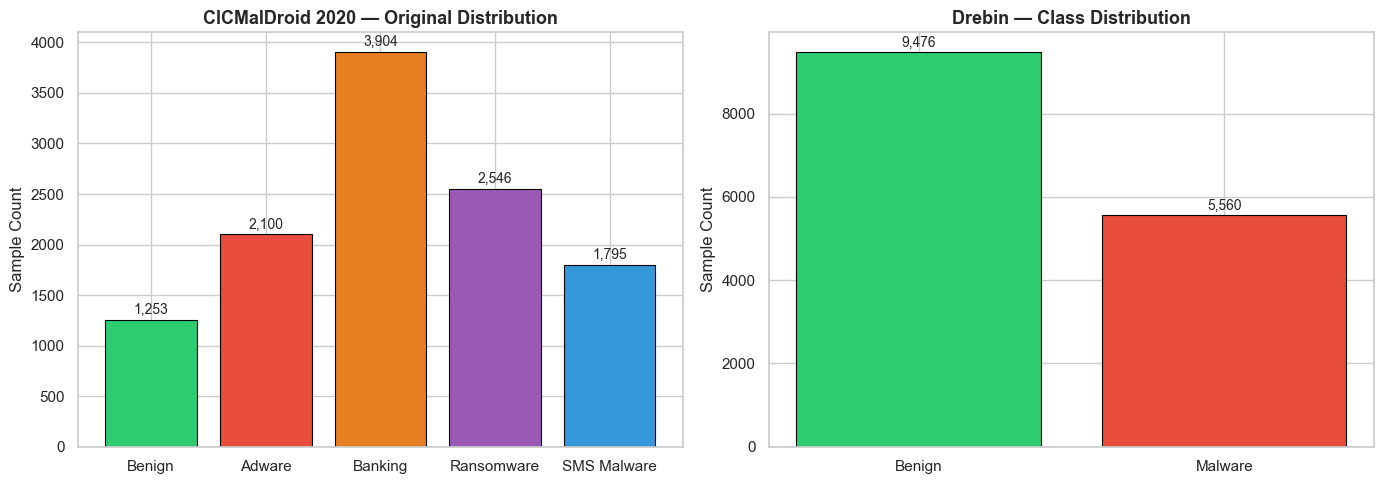

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# CICMalDroid — 5-class distribution
cic_counts = cic_df['Class'].value_counts().sort_index()
labels_cic  = [CIC_CLASS_NAMES[int(k)] for k in cic_counts.index]
colors_cic  = ['#2ecc71', '#e74c3c', '#e67e22', '#9b59b6', '#3498db']
bars = axes[0].bar(labels_cic, cic_counts.values, color=colors_cic,
                   edgecolor='black', linewidth=0.8)
axes[0].set_title('CICMalDroid 2020 — Original Distribution', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sample Count')
for bar, v in zip(bars, cic_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 30,
                 f'{v:,}', ha='center', va='bottom', fontsize=10)

# Drebin — binary distribution
drebin_counts = drebin_df['class'].value_counts()
labels_dr     = [DREBIN_CLASS_NAMES[k] for k in drebin_counts.index]
colors_dr     = ['#2ecc71', '#e74c3c']
bars2 = axes[1].bar(labels_dr, drebin_counts.values, color=colors_dr,
                    edgecolor='black', linewidth=0.8)
axes[1].set_title('Drebin — Class Distribution', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Sample Count')
for bar, v in zip(bars2, drebin_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 50,
                 f'{v:,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(PROCESSED_DIR, 'eda_class_distribution.png'), bbox_inches='tight')
plt.show()

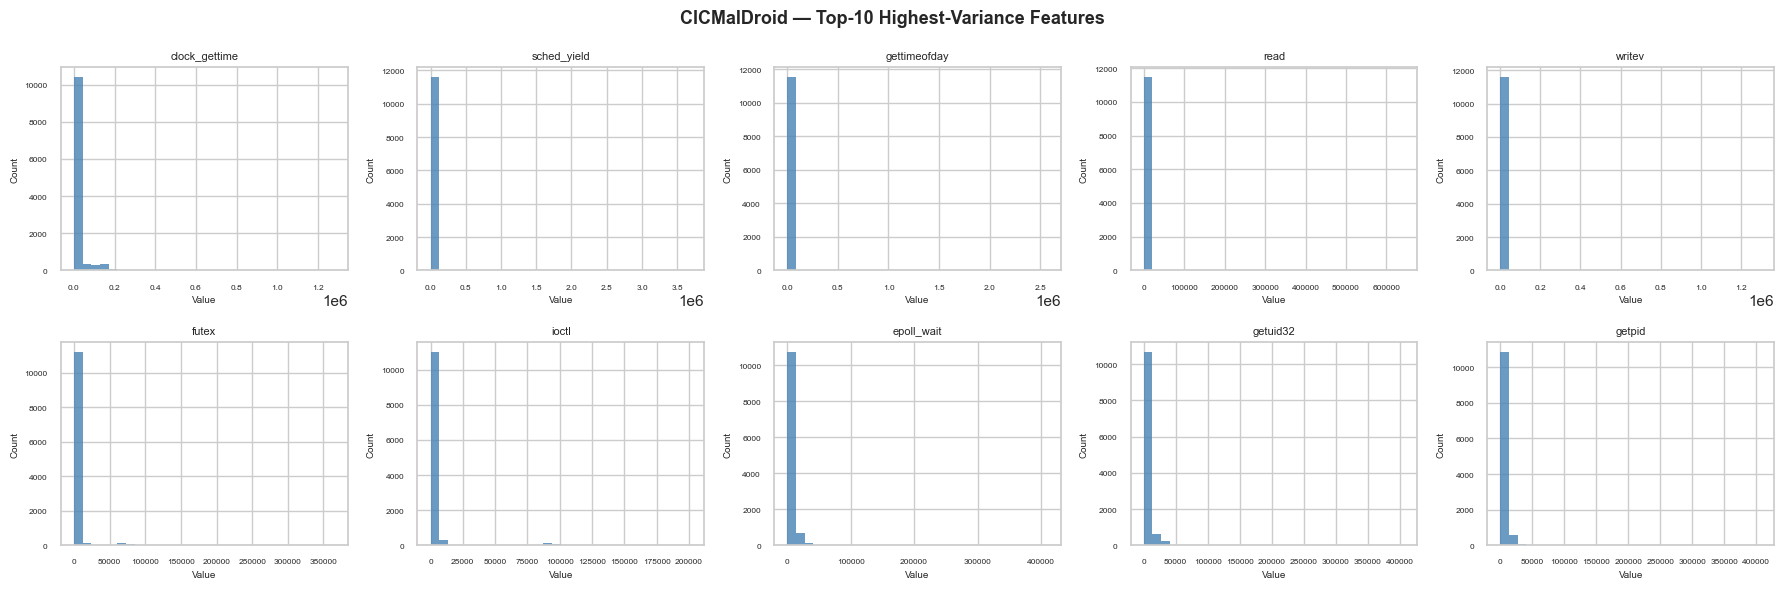

In [108]:
# Top-10 highest-variance CICMalDroid features
top10 = (cic_df[cic_feat_cols].var()
         .sort_values(ascending=False)
         .head(10))

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
fig.suptitle('CICMalDroid — Top-10 Highest-Variance Features', fontsize=13, fontweight='bold')

for ax, feat in zip(axes.flatten(), top10.index):
    ax.hist(cic_df[feat], bins=30, color='steelblue', edgecolor='none', alpha=0.8)
    ax.set_title(feat[:25], fontsize=8)
    ax.set_xlabel('Value', fontsize=7)
    ax.set_ylabel('Count',  fontsize=7)
    ax.tick_params(labelsize=6)

plt.tight_layout()
plt.savefig(os.path.join(PROCESSED_DIR, 'eda_top10_features.png'), bbox_inches='tight')
plt.show()

---
## 2.5 Data Cleaning — Duplicates & Label Conflicts

**Issues found in raw data (must be fixed BEFORE the train/test split):**

| Dataset | Exact duplicates | Label conflicts | Cross-split leak (before fix) |
|---|---|---|---|
| CICMalDroid | 72 rows | 5 rows | 17 / 2,320 test rows (0.7 %) |
| Drebin | 7,775 rows | 2 rows | **1,903 / 3,008 test rows (63.3 %)** |

**Cleaning order:**
1. Identify feature vectors that map to more than one label → remove all copies (label noise)
2. Remove exact duplicate rows (same features **and** same label)

In [109]:
def audit_dataframe(df, feat_cols, label_col, name):
    n_total      = len(df)
    n_exact_dup  = df.duplicated().sum()
    feat_dup_mask = df.duplicated(subset=feat_cols, keep=False)
    full_dup_mask = df.duplicated(keep=False)
    n_conflicts   = (feat_dup_mask & ~full_dup_mask).sum()
    print(f"{name}")
    print(f"  Total rows         : {n_total:,}")
    print(f"  Exact duplicates   : {n_exact_dup:,}  (rows to remove)")
    print(f"  Label conflicts    : {n_conflicts}  (same features, different class)")
    print(f"  Rows after clean   : {n_total - n_exact_dup - n_conflicts:,}")

print("=" * 50)
print("DUPLICATE & CONFLICT AUDIT")
print("=" * 50)
audit_dataframe(cic_df,    cic_feat_cols,    'Class', 'CICMalDroid')
print()
audit_dataframe(drebin_df, drebin_feat_cols, 'class', 'Drebin')

DUPLICATE & CONFLICT AUDIT
CICMalDroid
  Total rows         : 11,598
  Exact duplicates   : 72  (rows to remove)
  Label conflicts    : 5  (same features, different class)
  Rows after clean   : 11,521

Drebin
  Total rows         : 15,036
  Exact duplicates   : 7,775  (rows to remove)
  Label conflicts    : 2  (same features, different class)
  Rows after clean   : 7,259


In [110]:
def clean_dataframe(df, feat_cols, label_col, name):
    n_before = len(df)
    df = df.copy()

    # Step 1 — remove label conflicts using feature hash
    feat_hash = pd.util.hash_pandas_object(df[feat_cols], index=False)
    df['_hash'] = feat_hash.values
    label_per_hash = df.groupby('_hash')[label_col].nunique()
    conflict_hashes = label_per_hash[label_per_hash > 1].index
    n_conflicts = df['_hash'].isin(conflict_hashes).sum()
    df = df[~df['_hash'].isin(conflict_hashes)].drop(columns=['_hash'])

    # Step 2 — remove exact duplicates
    n_pre_dedup = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    n_dedup = n_pre_dedup - len(df)

    print(f"{name}: {n_before:,} -> {len(df):,} "
          f"(removed {n_conflicts} label conflicts + {n_dedup} exact duplicates)")
    return df

cic_df    = clean_dataframe(cic_df,    cic_feat_cols,    'Class', 'CICMalDroid')
drebin_df = clean_dataframe(drebin_df, drebin_feat_cols, 'class', 'Drebin')

print()
print("Class distribution after cleaning:")
print("  CICMalDroid:", cic_df['Class'].value_counts().sort_index().to_dict())
print("  Drebin     :", drebin_df['class'].value_counts().to_dict())

CICMalDroid: 11,598 -> 11,518 (removed 39 label conflicts + 41 exact duplicates)
Drebin: 15,036 -> 7,255 (removed 398 label conflicts + 7383 exact duplicates)

Class distribution after cleaning:
  CICMalDroid: {1: 1251, 2: 2043, 3: 3902, 4: 2531, 5: 1791}
  Drebin     : {'B': 5537, 'S': 1718}


---
## 3. Binary Label Mapping

CICMalDroid has **5 categories**.  For binary malware detection we collapse them:

| Original class | Category | Binary label |
|---|---|---|
| 1 | Benign | **0 — Benign** |
| 2 | Adware | **1 — Malware** |
| 3 | Banking Malware | **1 — Malware** |
| 4 | Ransomware | **1 — Malware** |
| 5 | SMS Malware | **1 — Malware** |

Drebin is already binary (`B` = Benign, `S` = Malware).

In [111]:
CIC_BINARY_MAP = {1: 0, 2: 1, 3: 1, 4: 1, 5: 1}
cic_df['label'] = cic_df['Class'].map(CIC_BINARY_MAP)

bin_counts_cic = cic_df['label'].value_counts().sort_index()
print("CICMalDroid — Binary class distribution:")
for lbl, cnt in bin_counts_cic.items():
    tag = 'Benign' if lbl == 0 else 'Malware'
    print(f"  {lbl} ({tag}): {cnt:,}  ({cnt/len(cic_df)*100:.1f}%)")
print(f"\n  Imbalance ratio (Malware:Benign): "
      f"{bin_counts_cic[1]/bin_counts_cic[0]:.2f}:1")

CICMalDroid — Binary class distribution:
  0 (Benign): 1,251  (10.9%)
  1 (Malware): 10,267  (89.1%)

  Imbalance ratio (Malware:Benign): 8.21:1


In [112]:
# Fix missing values and convert to numeric
drebin_df.replace('?', 0, inplace=True)
drebin_df[drebin_feat_cols] = (drebin_df[drebin_feat_cols]
                               .apply(pd.to_numeric, errors='coerce')
                               .fillna(0))

drebin_df['label'] = drebin_df['class'].map({'B': 0, 'S': 1})

bin_counts_drebin = drebin_df['label'].value_counts().sort_index()
print("Drebin — Binary class distribution:")
for lbl, cnt in bin_counts_drebin.items():
    tag = 'Benign' if lbl == 0 else 'Malware'
    print(f"  {lbl} ({tag}): {cnt:,}  ({cnt/len(drebin_df)*100:.1f}%)")
print(f"\n  Imbalance ratio (Benign:Malware): "
      f"{bin_counts_drebin[0]/bin_counts_drebin[1]:.2f}:1")

Drebin — Binary class distribution:
  0 (Benign): 5,537  (76.3%)
  1 (Malware): 1,718  (23.7%)

  Imbalance ratio (Benign:Malware): 3.22:1


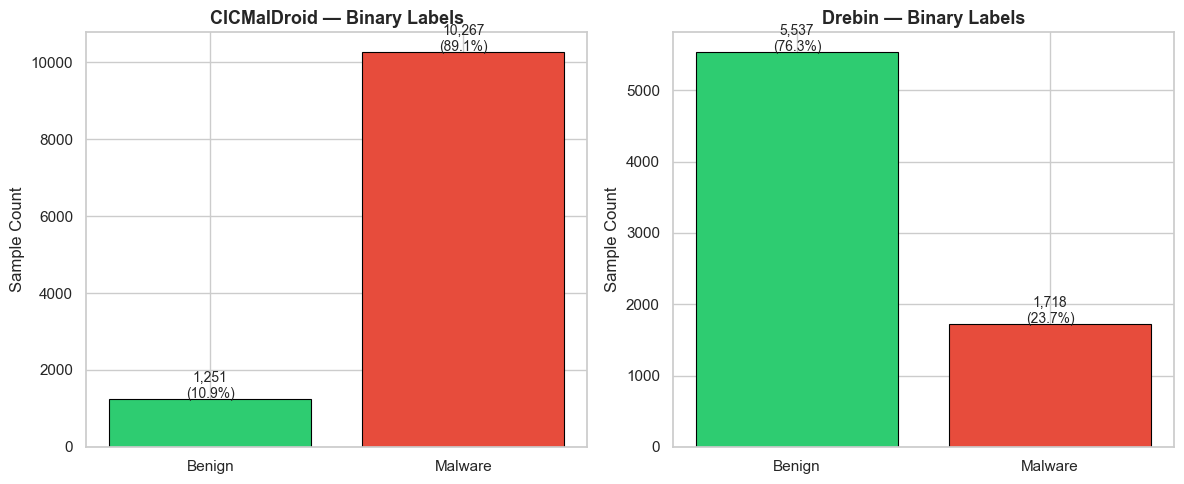

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, counts, title, total in [
    (axes[0], bin_counts_cic,    'CICMalDroid — Binary Labels', len(cic_df)),
    (axes[1], bin_counts_drebin, 'Drebin — Binary Labels',      len(drebin_df)),
]:
    bars = ax.bar(['Benign', 'Malware'], [counts[0], counts[1]],
                  color=['#2ecc71', '#e74c3c'], edgecolor='black', linewidth=0.8)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('Sample Count')
    for bar, v in zip(bars, [counts[0], counts[1]]):
        ax.text(bar.get_x() + bar.get_width()/2, v + 20,
                f'{v:,}\n({v/total*100:.1f}%)', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(PROCESSED_DIR, 'binary_class_distribution.png'), bbox_inches='tight')
plt.show()

---
## 4. Train / Validation / Test Split

Stratified split to preserve class balance in every subset:

| Subset | Fraction |
|---|---|
| Train | 70 % |
| Validation | 10 % |
| Test | 20 % |

`random_state=42` ensures reproducibility.

In [114]:
X_cic    = cic_df[cic_feat_cols].values.astype(np.float32)
y_cic    = cic_df['label'].values.astype(np.int64)

X_drebin = drebin_df[drebin_feat_cols].values.astype(np.float32)
y_drebin = drebin_df['label'].values.astype(np.int64)

def stratified_split(X, y, test_size=TEST_SIZE, val_frac=VAL_FRAC,
                     random_state=RANDOM_STATE):
    """70/10/20 stratified split."""
    X_tv, X_te, y_tv, y_te = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y)
    X_tr, X_v, y_tr, y_v = train_test_split(
        X_tv, y_tv, test_size=val_frac, random_state=random_state, stratify=y_tv)
    return X_tr, X_v, X_te, y_tr, y_v, y_te

(X_cic_train, X_cic_val, X_cic_test,
 y_cic_train, y_cic_val, y_cic_test) = stratified_split(X_cic, y_cic)

(X_drebin_train, X_drebin_val, X_drebin_test,
 y_drebin_train, y_drebin_val, y_drebin_test) = stratified_split(X_drebin, y_drebin)

print(f"{'Dataset':<14} {'Split':<8} {'Samples':>8}  {'Benign':>8}  {'Malware':>8}")
print("-" * 55)
for name, splits in [
    ("CICMalDroid", [(X_cic_train,  y_cic_train,  'Train'),
                     (X_cic_val,    y_cic_val,    'Val  '),
                     (X_cic_test,   y_cic_test,   'Test ')]),
    ("Drebin",      [(X_drebin_train, y_drebin_train, 'Train'),
                     (X_drebin_val,   y_drebin_val,   'Val  '),
                     (X_drebin_test,  y_drebin_test,  'Test ')]),
]:
    for X, y, tag in splits:
        print(f"  {name:<12} {tag:<8} {len(X):>8,}  "
              f"{int(np.sum(y==0)):>8,}  {int(np.sum(y==1)):>8,}")
    print()

Dataset        Split     Samples    Benign   Malware
-------------------------------------------------------
  CICMalDroid  Train       8,062       876     7,186
  CICMalDroid  Val         1,152       125     1,027
  CICMalDroid  Test        2,304       250     2,054

  Drebin       Train       5,078     3,876     1,202
  Drebin       Val           726       554       172
  Drebin       Test        1,451     1,107       344



---
## 5. Feature Scaling — StandardScaler

Standardisation (zero mean, unit variance) is applied **per dataset**.  
The scaler is **fit on the training set only** and then applied to validation and test sets to prevent data leakage.

In [115]:
scaler_cic    = StandardScaler()
scaler_drebin = StandardScaler()

X_cic_train_sc = scaler_cic.fit_transform(X_cic_train)
X_cic_val_sc   = scaler_cic.transform(X_cic_val)
X_cic_test_sc  = scaler_cic.transform(X_cic_test)

X_drebin_train_sc = scaler_drebin.fit_transform(X_drebin_train)
X_drebin_val_sc   = scaler_drebin.transform(X_drebin_val)
X_drebin_test_sc  = scaler_drebin.transform(X_drebin_test)

print("StandardScaler applied.")
print(f"  CICMalDroid — train mean (post-scale): "
      f"{X_cic_train_sc.mean():.6f}  std: {X_cic_train_sc.std():.6f}")
print(f"  Drebin      — train mean (post-scale): "
      f"{X_drebin_train_sc.mean():.6f}  std: {X_drebin_train_sc.std():.6f}")

StandardScaler applied.
  CICMalDroid — train mean (post-scale): 0.000000  std: 0.977404
  Drebin      — train mean (post-scale): 0.000000  std: 1.000000


---
## 6. Feature Selection — Variance Threshold

Features with variance below **0.01** (after scaling) are removed.  
These near-constant features carry negligible discriminative information and can impair model generalisation.  
The selector is fit on the **scaled training set** only.

In [116]:
vt_cic    = VarianceThreshold(threshold=VAR_THRESHOLD)
vt_drebin = VarianceThreshold(threshold=VAR_THRESHOLD)

X_cic_train_f = vt_cic.fit_transform(X_cic_train_sc)
X_cic_val_f   = vt_cic.transform(X_cic_val_sc)
X_cic_test_f  = vt_cic.transform(X_cic_test_sc)

X_drebin_train_f = vt_drebin.fit_transform(X_drebin_train_sc)
X_drebin_val_f   = vt_drebin.transform(X_drebin_val_sc)
X_drebin_test_f  = vt_drebin.transform(X_drebin_test_sc)

selected_cic    = [cic_feat_cols[i]    for i in vt_cic.get_support(indices=True)]
selected_drebin = [drebin_feat_cols[i] for i in vt_drebin.get_support(indices=True)]

print(f"Variance threshold = {VAR_THRESHOLD}")
print(f"\nCICMalDroid : {len(cic_feat_cols):>4} -> {len(selected_cic):>4} features "
      f"(removed {len(cic_feat_cols) - len(selected_cic)})")
print(f"Drebin      : {len(drebin_feat_cols):>4} -> {len(selected_drebin):>4} features "
      f"(removed {len(drebin_feat_cols) - len(selected_drebin)})")
print(f"\nFinal array shapes:")
print(f"  CICMalDroid — train={X_cic_train_f.shape}, "
      f"val={X_cic_val_f.shape}, test={X_cic_test_f.shape}")
print(f"  Drebin      — train={X_drebin_train_f.shape}, "
      f"val={X_drebin_val_f.shape}, test={X_drebin_test_f.shape}")

Variance threshold = 0.01

CICMalDroid :  470 ->  449 features (removed 21)
Drebin      :  215 ->  215 features (removed 0)

Final array shapes:
  CICMalDroid — train=(8062, 449), val=(1152, 449), test=(2304, 449)
  Drebin      — train=(5078, 215), val=(726, 215), test=(1451, 215)


---
## 7. Save Processed Artefacts

All arrays, scalers, selectors, and feature lists are persisted to `processed/` for use in the model-training notebook.

| Prefix | Dataset |
|---|---|
| `cic` | CICMalDroid 2020 (binary, all features) |
| `drebin` | Drebin (binary, API-presence features) |

In [117]:
artefacts = {
    'cic': {
        'X_train': X_cic_train_f,  'X_val': X_cic_val_f,  'X_test': X_cic_test_f,
        'y_train': y_cic_train,    'y_val': y_cic_val,    'y_test': y_cic_test,
        'scaler': scaler_cic, 'vt': vt_cic, 'features': selected_cic,
    },
    'drebin': {
        'X_train': X_drebin_train_f, 'X_val': X_drebin_val_f, 'X_test': X_drebin_test_f,
        'y_train': y_drebin_train,   'y_val': y_drebin_val,   'y_test': y_drebin_test,
        'scaler': scaler_drebin, 'vt': vt_drebin, 'features': selected_drebin,
    },
}

for prefix, d in artefacts.items():
    for split in ['train', 'val', 'test']:
        np.save(f"{PROCESSED_DIR}/{prefix}_X_{split}.npy", d[f'X_{split}'])
        np.save(f"{PROCESSED_DIR}/{prefix}_y_{split}.npy", d[f'y_{split}'])
    joblib.dump(d['scaler'], f"{PROCESSED_DIR}/{prefix}_scaler.joblib")
    joblib.dump(d['vt'],     f"{PROCESSED_DIR}/{prefix}_variance_selector.joblib")
    with open(f"{PROCESSED_DIR}/{prefix}_features.json", 'w') as fh:
        json.dump(d['features'], fh, indent=2)
    print(f"[{prefix}] saved — train={d['X_train'].shape}, "
          f"val={d['X_val'].shape}, test={d['X_test'].shape}")

print(f"\nAll artefacts written to '{PROCESSED_DIR}/'.")

[cic] saved — train=(8062, 449), val=(1152, 449), test=(2304, 449)
[drebin] saved — train=(5078, 215), val=(726, 215), test=(1451, 215)

All artefacts written to 'processed/'.


In [118]:
print("=" * 65)
print("PREPROCESSING SUMMARY")
print("=" * 65)
for prefix, d in artefacts.items():
    X_tr, X_v, X_te = d['X_train'], d['X_val'], d['X_test']
    y_tr, y_v, y_te = d['y_train'], d['y_val'], d['y_test']
    total = len(X_tr) + len(X_v) + len(X_te)
    print(f"\n  {prefix.upper()} ({total:,} samples, {X_tr.shape[1]} features)")
    for tag, X, y in [('Train', X_tr, y_tr), ('Val  ', X_v, y_v), ('Test ', X_te, y_te)]:
        pct = len(X) / total * 100
        print(f"    {tag}: {len(X):5,} ({pct:4.1f}%)  "
              f"Benign={int(np.sum(y==0)):,}  Malware={int(np.sum(y==1)):,}")

print()
print("  Saved files:")
for prefix in artefacts:
    for name in ['X_train','X_val','X_test','y_train','y_val','y_test']:
        print(f"    processed/{prefix}_{name}.npy")
    for name in ['scaler.joblib','variance_selector.joblib','features.json']:
        print(f"    processed/{prefix}_{name}")

print("\nPreprocessing complete. Proceed to model training notebook.")

PREPROCESSING SUMMARY

  CIC (11,518 samples, 449 features)
    Train: 8,062 (70.0%)  Benign=876  Malware=7,186
    Val  : 1,152 (10.0%)  Benign=125  Malware=1,027
    Test : 2,304 (20.0%)  Benign=250  Malware=2,054

  DREBIN (7,255 samples, 215 features)
    Train: 5,078 (70.0%)  Benign=3,876  Malware=1,202
    Val  :   726 (10.0%)  Benign=554  Malware=172
    Test : 1,451 (20.0%)  Benign=1,107  Malware=344

  Saved files:
    processed/cic_X_train.npy
    processed/cic_X_val.npy
    processed/cic_X_test.npy
    processed/cic_y_train.npy
    processed/cic_y_val.npy
    processed/cic_y_test.npy
    processed/cic_scaler.joblib
    processed/cic_variance_selector.joblib
    processed/cic_features.json
    processed/drebin_X_train.npy
    processed/drebin_X_val.npy
    processed/drebin_X_test.npy
    processed/drebin_y_train.npy
    processed/drebin_y_val.npy
    processed/drebin_y_test.npy
    processed/drebin_scaler.joblib
    processed/drebin_variance_selector.joblib
    processed/dreb

---
## 8. Random Forest Classifier

**Strategy**
- `class_weight='balanced'` to handle CICMalDroid imbalance (Benign:Malware ≈ 1:8.3)
- Hyperparameter search via `RandomizedSearchCV` (cv=3, n_iter=20, scoring=`f1_weighted`)
- Best model retrained on **train + val** before final test-set evaluation
- Same pipeline applied independently to both datasets


In [119]:
import numpy as np
import json, joblib, os, time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, auc)

PROCESSED_DIR = 'processed'
MODELS_DIR    = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)

# ── Load CICMalDroid ──────────────────────────────────────────
X_cic_train = np.load(f'{PROCESSED_DIR}/cic_X_train.npy')
X_cic_val   = np.load(f'{PROCESSED_DIR}/cic_X_val.npy')
X_cic_test  = np.load(f'{PROCESSED_DIR}/cic_X_test.npy')
y_cic_train = np.load(f'{PROCESSED_DIR}/cic_y_train.npy')
y_cic_val   = np.load(f'{PROCESSED_DIR}/cic_y_val.npy')
y_cic_test  = np.load(f'{PROCESSED_DIR}/cic_y_test.npy')

with open(f'{PROCESSED_DIR}/cic_features.json') as fh:
    cic_features = json.load(fh)

# ── Load Drebin ───────────────────────────────────────────────
X_drebin_train = np.load(f'{PROCESSED_DIR}/drebin_X_train.npy')
X_drebin_val   = np.load(f'{PROCESSED_DIR}/drebin_X_val.npy')
X_drebin_test  = np.load(f'{PROCESSED_DIR}/drebin_X_test.npy')
y_drebin_train = np.load(f'{PROCESSED_DIR}/drebin_y_train.npy')
y_drebin_val   = np.load(f'{PROCESSED_DIR}/drebin_y_val.npy')
y_drebin_test  = np.load(f'{PROCESSED_DIR}/drebin_y_test.npy')

with open(f'{PROCESSED_DIR}/drebin_features.json') as fh:
    drebin_features = json.load(fh)

print(f"CIC    — train={X_cic_train.shape}  val={X_cic_val.shape}  test={X_cic_test.shape}")
print(f"Drebin — train={X_drebin_train.shape}  val={X_drebin_val.shape}  test={X_drebin_test.shape}")


CIC    — train=(8062, 449)  val=(1152, 449)  test=(2304, 449)
Drebin — train=(5078, 215)  val=(726, 215)  test=(1451, 215)


In [120]:
def evaluate(model, X, y, label=''):
    """Return metric dict and raw predictions."""
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    m = {
        'Accuracy' : accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall'   : recall_score(y, y_pred, zero_division=0),
        'F1'       : f1_score(y, y_pred, zero_division=0),
        'F1-W'     : f1_score(y, y_pred, average='weighted', zero_division=0),
        'ROC-AUC'  : roc_auc_score(y, y_prob),
    }
    if label:
        print(f"  {label}")
        for k, v in m.items():
            print(f"    {k:<12}: {v:.4f}")
    return m, y_pred, y_prob

rf_results = {}   # stores final metrics for both datasets
print("Helper functions defined.")


Helper functions defined.


### 8.1 CICMalDroid 2020


In [121]:
print("Baseline RF (default params, class_weight='balanced') …")
t0 = time.time()

rf_base = RandomForestClassifier(
    n_estimators=100, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf_base.fit(X_cic_train, y_cic_train)

m_val, _, _ = evaluate(rf_base, X_cic_val, y_cic_val, 'Baseline — Val')
print(f"  Fit time: {time.time()-t0:.1f}s")


Baseline RF (default params, class_weight='balanced') …
  Baseline — Val
    Accuracy    : 0.9766
    Precision   : 0.9798
    Recall      : 0.9942
    F1          : 0.9870
    F1-W        : 0.9759
    ROC-AUC     : 0.9947
  Fit time: 0.2s


In [122]:
# ~3-5 min with n_jobs=-1
print("RandomizedSearchCV (n_iter=20, cv=3, scoring=f1_weighted) …")

param_dist = {
    'n_estimators'     : [100, 200, 300],
    'max_depth'        : [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 2, 4],
    'max_features'     : ['sqrt', 'log2'],
}

search_cic = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=20, cv=3,
    scoring='f1_weighted',
    random_state=42, n_jobs=-1, verbose=1,
    refit=True
)

t0 = time.time()
search_cic.fit(X_cic_train, y_cic_train)
print(f"\nSearch done in {time.time()-t0:.1f}s")
print(f"Best val CV F1-weighted : {search_cic.best_score_:.4f}")
print(f"Best params             : {search_cic.best_params_}")


RandomizedSearchCV (n_iter=20, cv=3, scoring=f1_weighted) …
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Search done in 8.7s
Best val CV F1-weighted : 0.9709
Best params             : {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}


In [123]:
# Combine train + val, retrain with best params, evaluate on held-out test
best_params_cic = search_cic.best_params_

X_cic_tv = np.vstack([X_cic_train, X_cic_val])
y_cic_tv  = np.concatenate([y_cic_train, y_cic_val])

rf_cic = RandomForestClassifier(
    **best_params_cic,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_cic.fit(X_cic_tv, y_cic_tv)

print("CICMalDroid RF — Final Evaluation")
print("=" * 45)
m_cic, y_cic_pred, y_cic_prob = evaluate(rf_cic, X_cic_test, y_cic_test, 'Test Set')
rf_results['cic'] = m_cic

print(f"\nClassification Report:")
print(classification_report(y_cic_test, y_cic_pred,
                             target_names=['Benign', 'Malware']))


CICMalDroid RF — Final Evaluation
  Test Set
    Accuracy    : 0.9826
    Precision   : 0.9893
    Recall      : 0.9912
    F1          : 0.9903
    F1-W        : 0.9826
    ROC-AUC     : 0.9967

Classification Report:
              precision    recall  f1-score   support

      Benign       0.93      0.91      0.92       250
     Malware       0.99      0.99      0.99      2054

    accuracy                           0.98      2304
   macro avg       0.96      0.95      0.95      2304
weighted avg       0.98      0.98      0.98      2304



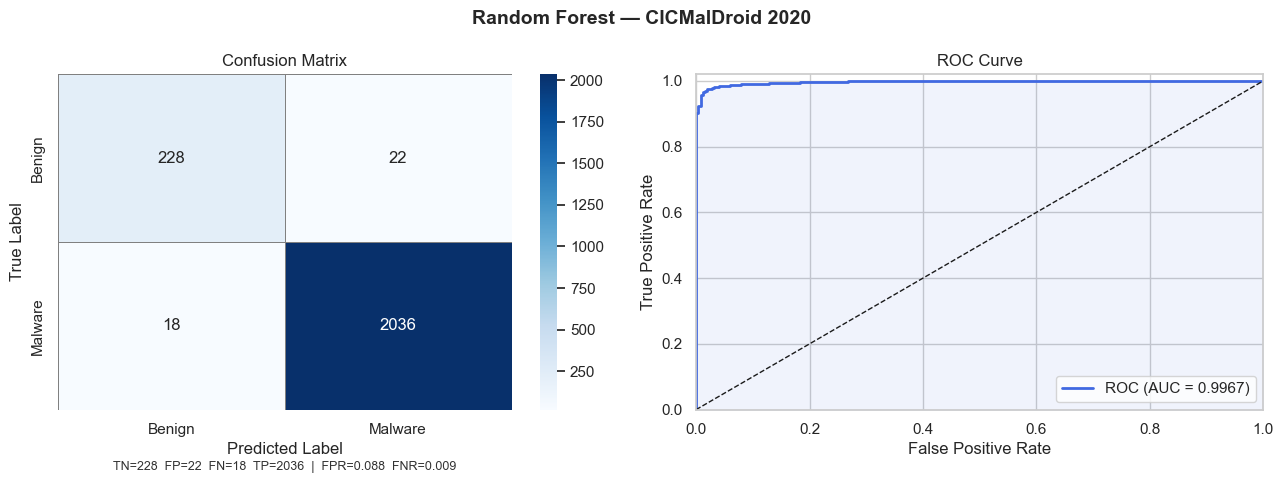

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Random Forest — CICMalDroid 2020', fontsize=14, fontweight='bold')

# Confusion matrix
cm = confusion_matrix(y_cic_test, y_cic_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray')
axes[0].set_title('Confusion Matrix', fontsize=12)
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

tn, fp, fn, tp = cm.ravel()
axes[0].text(0.5, -0.18,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=axes[0].transAxes, ha='center', fontsize=9, color='#333')

# ROC curve
fpr, tpr, _ = roc_curve(y_cic_test, y_cic_prob)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='royalblue', lw=2,
             label=f'ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].fill_between(fpr, tpr, alpha=0.08, color='royalblue')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontsize=12)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'rf_cic_eval.png'), bbox_inches='tight')
plt.show()


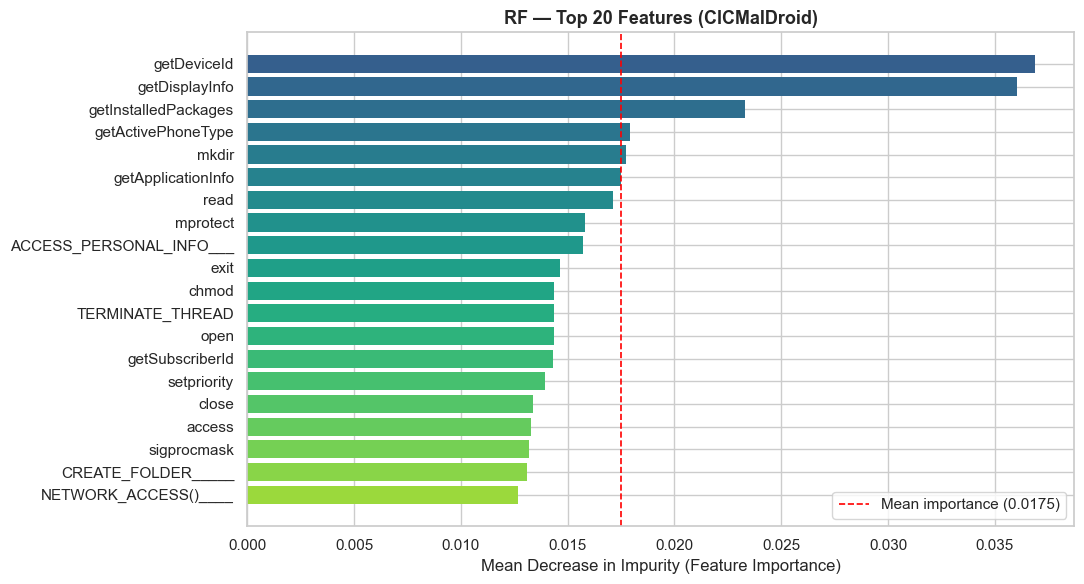

In [125]:
importances = rf_cic.feature_importances_
top_n = 20
idx = np.argsort(importances)[::-1][:top_n]

fig, ax = plt.subplots(figsize=(11, 6))
colors = plt.cm.viridis(np.linspace(0.3, 0.85, top_n))
bars = ax.barh([cic_features[i][:35] for i in idx[::-1]],
               importances[idx[::-1]], color=colors[::-1], edgecolor='none')
ax.set_xlabel('Mean Decrease in Impurity (Feature Importance)')
ax.set_title(f'RF — Top {top_n} Features (CICMalDroid)', fontsize=13, fontweight='bold')
ax.axvline(importances[idx].mean(), color='red', linestyle='--',
           linewidth=1.2, label=f'Mean importance ({importances[idx].mean():.4f})')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'rf_cic_feature_importance.png'), bbox_inches='tight')
plt.show()


### 8.2 Drebin (Secondary Dataset)


In [126]:
print("RandomizedSearchCV on Drebin (n_iter=20, cv=3) …")

search_drebin = RandomizedSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=20, cv=3,
    scoring='f1_weighted',
    random_state=42, n_jobs=-1, verbose=1,
    refit=True
)

t0 = time.time()
search_drebin.fit(X_drebin_train, y_drebin_train)
print(f"\nSearch done in {time.time()-t0:.1f}s")
print(f"Best CV F1-weighted : {search_drebin.best_score_:.4f}")
print(f"Best params         : {search_drebin.best_params_}")

# Retrain on train+val
best_params_drebin = search_drebin.best_params_
X_drebin_tv = np.vstack([X_drebin_train, X_drebin_val])
y_drebin_tv  = np.concatenate([y_drebin_train, y_drebin_val])

rf_drebin = RandomForestClassifier(
    **best_params_drebin,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_drebin.fit(X_drebin_tv, y_drebin_tv)

print("\nDrebin RF — Final Evaluation")
print("=" * 45)
m_drebin, y_drebin_pred, y_drebin_prob = evaluate(rf_drebin, X_drebin_test, y_drebin_test, 'Test Set')
rf_results['drebin'] = m_drebin

print(f"\nClassification Report:")
print(classification_report(y_drebin_test, y_drebin_pred,
                             target_names=['Benign', 'Malware']))


RandomizedSearchCV on Drebin (n_iter=20, cv=3) …
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Search done in 3.1s
Best CV F1-weighted : 0.9670
Best params         : {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}

Drebin RF — Final Evaluation
  Test Set
    Accuracy    : 0.9738
    Precision   : 0.9722
    Recall      : 0.9157
    F1          : 0.9431
    F1-W        : 0.9735
    ROC-AUC     : 0.9940

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98      1107
     Malware       0.97      0.92      0.94       344

    accuracy                           0.97      1451
   macro avg       0.97      0.95      0.96      1451
weighted avg       0.97      0.97      0.97      1451



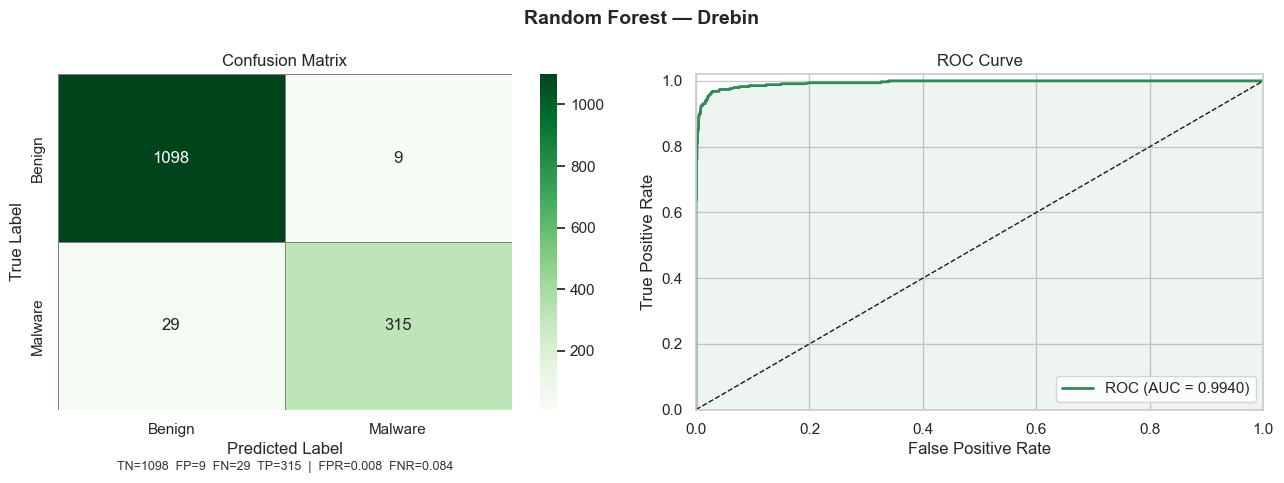

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Random Forest — Drebin', fontsize=14, fontweight='bold')

cm_d = confusion_matrix(y_drebin_test, y_drebin_pred)
sns.heatmap(cm_d, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray')
axes[0].set_title('Confusion Matrix')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
tn, fp, fn, tp = cm_d.ravel()
axes[0].text(0.5, -0.18,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=axes[0].transAxes, ha='center', fontsize=9, color='#333')

fpr_d, tpr_d, _ = roc_curve(y_drebin_test, y_drebin_prob)
roc_auc_d = auc(fpr_d, tpr_d)
axes[1].plot(fpr_d, tpr_d, color='seagreen', lw=2,
             label=f'ROC (AUC = {roc_auc_d:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].fill_between(fpr_d, tpr_d, alpha=0.08, color='seagreen')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'rf_drebin_eval.png'), bbox_inches='tight')
plt.show()


In [128]:
joblib.dump(rf_cic,    f'{MODELS_DIR}/rf_cic.joblib')
joblib.dump(rf_drebin, f'{MODELS_DIR}/rf_drebin.joblib')
print(f"Models saved to '{MODELS_DIR}/'")

print("\n" + "=" * 55)
print("RANDOM FOREST — SUMMARY")
print("=" * 55)
print(f"  {'Metric':<14}  {'CICMalDroid':>12}  {'Drebin':>10}")
print("  " + "-" * 42)
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'F1-W', 'ROC-AUC']:
    cic_v    = rf_results['cic'][metric]
    drebin_v = rf_results['drebin'][metric]
    print(f"  {metric:<14}  {cic_v:>12.4f}  {drebin_v:>10.4f}")


Models saved to 'models/'

RANDOM FOREST — SUMMARY
  Metric           CICMalDroid      Drebin
  ------------------------------------------
  Accuracy              0.9826      0.9738
  Precision             0.9893      0.9722
  Recall                0.9912      0.9157
  F1                    0.9903      0.9431
  F1-W                  0.9826      0.9735
  ROC-AUC               0.9967      0.9940


## 9. XGBoost Classifier

**Strategy**
- `scale_pos_weight = n_negative / n_positive` to handle class imbalance (replaces `class_weight` which XGBoost does not support)
- `tree_method='hist'` for fast histogram-based training
- Same `RandomizedSearchCV` (cv=3, n_iter=20, scoring=`f1_weighted`) pattern as RF
- Best model retrained on **train + val** before final test-set evaluation


In [129]:
from xgboost import XGBClassifier
import xgboost as xgb

xgb_results = {}

# scale_pos_weight = n(negative) / n(positive) computed on training labels
spw_cic    = float(np.sum(y_cic_train == 0) / np.sum(y_cic_train == 1))
spw_drebin = float(np.sum(y_drebin_train == 0) / np.sum(y_drebin_train == 1))

print(f"XGBoost version: {xgb.__version__}")
print(f"\nCICMalDroid — Benign={int(np.sum(y_cic_train==0))}, "
      f"Malware={int(np.sum(y_cic_train==1))}")
print(f"  scale_pos_weight = {spw_cic:.4f}  (down-weights majority malware class)")
print(f"\nDrebin      — Benign={int(np.sum(y_drebin_train==0))}, "
      f"Malware={int(np.sum(y_drebin_train==1))}")
print(f"  scale_pos_weight = {spw_drebin:.4f}  (up-weights minority malware class)")


XGBoost version: 2.1.4

CICMalDroid — Benign=876, Malware=7186
  scale_pos_weight = 0.1219  (down-weights majority malware class)

Drebin      — Benign=3876, Malware=1202
  scale_pos_weight = 3.2246  (up-weights minority malware class)


### 9.1 CICMalDroid 2020


In [130]:
print("Baseline XGBClassifier …")
t0 = time.time()

xgb_base = XGBClassifier(
    n_estimators=100,
    scale_pos_weight=spw_cic,
    tree_method='hist',
    eval_metric='logloss',
    random_state=42, n_jobs=-1, verbosity=0
)
xgb_base.fit(X_cic_train, y_cic_train)

evaluate(xgb_base, X_cic_val, y_cic_val, 'Baseline — Val')
print(f"  Fit time: {time.time()-t0:.1f}s")


Baseline XGBClassifier …
  Baseline — Val
    Accuracy    : 0.9774
    Precision   : 0.9902
    Recall      : 0.9844
    F1          : 0.9873
    F1-W        : 0.9777
    ROC-AUC     : 0.9947
  Fit time: 0.3s


In [131]:
print("RandomizedSearchCV (n_iter=20, cv=3, scoring=f1_weighted) …")

param_dist_xgb = {
    'n_estimators'    : [100, 200, 300, 500],
    'max_depth'       : [3, 5, 6, 7, 9],
    'learning_rate'   : [0.01, 0.05, 0.1, 0.2],
    'subsample'       : [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'gamma'           : [0, 0.1, 0.2, 0.3],
    'reg_alpha'       : [0, 0.1, 0.5, 1.0],
    'reg_lambda'      : [0.5, 1.0, 5.0],
}

search_xgb_cic = RandomizedSearchCV(
    XGBClassifier(
        scale_pos_weight=spw_cic,
        tree_method='hist',
        eval_metric='logloss',
        random_state=42, n_jobs=-1, verbosity=0
    ),
    param_distributions=param_dist_xgb,
    n_iter=20, cv=3,
    scoring='f1_weighted',
    random_state=42, n_jobs=-1, verbose=1,
    refit=True
)

t0 = time.time()
search_xgb_cic.fit(X_cic_train, y_cic_train)
print(f"\nSearch done in {time.time()-t0:.1f}s")
print(f"Best CV F1-weighted : {search_xgb_cic.best_score_:.4f}")
print(f"Best params         : {search_xgb_cic.best_params_}")


RandomizedSearchCV (n_iter=20, cv=3, scoring=f1_weighted) …
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Search done in 9.0s
Best CV F1-weighted : 0.9759
Best params         : {'subsample': 0.8, 'reg_lambda': 0.5, 'reg_alpha': 0.5, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.6}


In [132]:
# Combine train + val, retrain with best params, evaluate on held-out test
X_cic_tv = np.vstack([X_cic_train, X_cic_val])
y_cic_tv  = np.concatenate([y_cic_train, y_cic_val])

xgb_cic = XGBClassifier(
    **search_xgb_cic.best_params_,
    scale_pos_weight=spw_cic,
    tree_method='hist',
    eval_metric='logloss',
    random_state=42, n_jobs=-1, verbosity=0
)
xgb_cic.fit(X_cic_tv, y_cic_tv)

print("CICMalDroid XGBoost — Final Evaluation")
print("=" * 45)
m_xgb_cic, y_xgb_cic_pred, y_xgb_cic_prob = evaluate(
    xgb_cic, X_cic_test, y_cic_test, 'Test Set')
xgb_results['cic'] = m_xgb_cic

print(f"\nClassification Report:")
print(classification_report(y_cic_test, y_xgb_cic_pred,
                             target_names=['Benign', 'Malware']))


CICMalDroid XGBoost — Final Evaluation
  Test Set
    Accuracy    : 0.9835
    Precision   : 0.9961
    Recall      : 0.9854
    F1          : 0.9907
    F1-W        : 0.9838
    ROC-AUC     : 0.9973

Classification Report:
              precision    recall  f1-score   support

      Benign       0.89      0.97      0.93       250
     Malware       1.00      0.99      0.99      2054

    accuracy                           0.98      2304
   macro avg       0.94      0.98      0.96      2304
weighted avg       0.98      0.98      0.98      2304



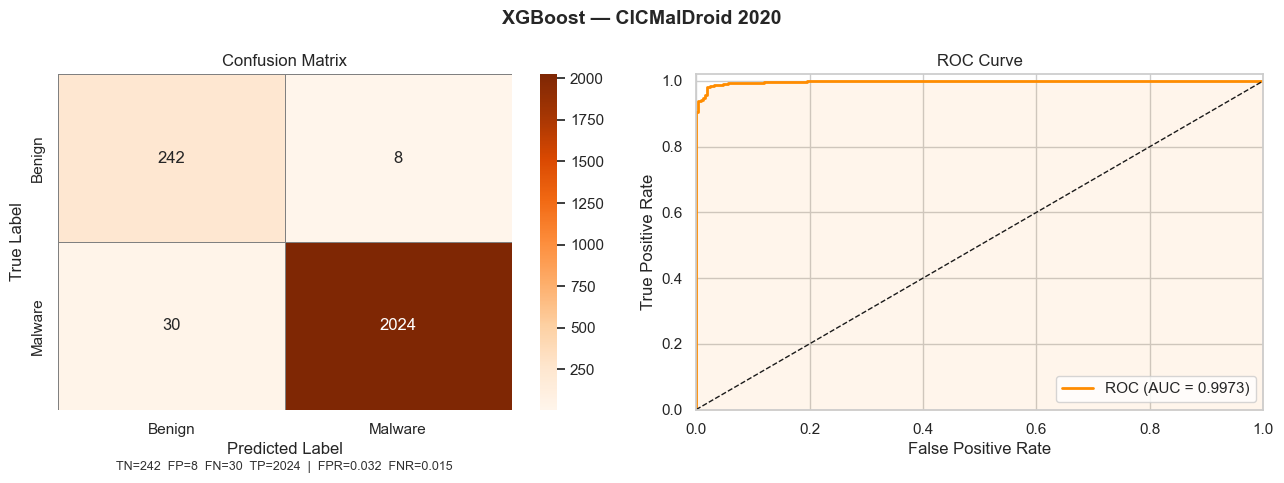

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('XGBoost — CICMalDroid 2020', fontsize=14, fontweight='bold')

cm_x = confusion_matrix(y_cic_test, y_xgb_cic_pred)
sns.heatmap(cm_x, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray')
axes[0].set_title('Confusion Matrix', fontsize=12)
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
tn, fp, fn, tp = cm_x.ravel()
axes[0].text(0.5, -0.18,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=axes[0].transAxes, ha='center', fontsize=9, color='#333')

fpr_x, tpr_x, _ = roc_curve(y_cic_test, y_xgb_cic_prob)
roc_auc_x = auc(fpr_x, tpr_x)
axes[1].plot(fpr_x, tpr_x, color='darkorange', lw=2,
             label=f'ROC (AUC = {roc_auc_x:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].fill_between(fpr_x, tpr_x, alpha=0.08, color='darkorange')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontsize=12)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'xgb_cic_eval.png'), bbox_inches='tight')
plt.show()


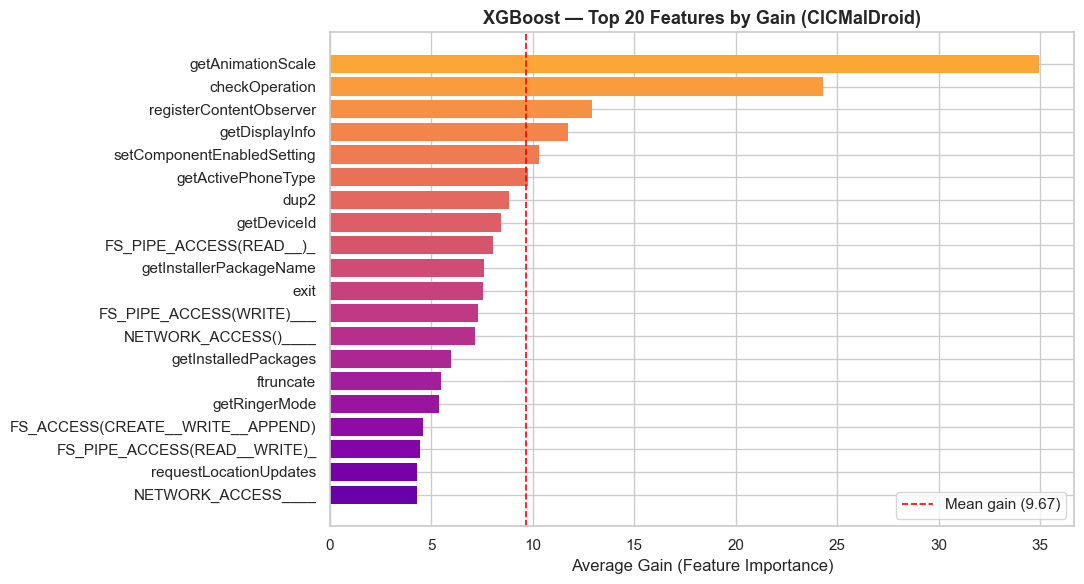

In [134]:
# XGBoost gain-based feature importance
gain_scores = xgb_cic.get_booster().get_score(importance_type='gain')
sorted_feats = sorted(gain_scores.items(), key=lambda x: x[1], reverse=True)[:20]

feat_names = [cic_features[int(k[1:])] if k.startswith('f') else k
              for k, _ in sorted_feats]
feat_vals  = [v for _, v in sorted_feats]

fig, ax = plt.subplots(figsize=(11, 6))
colors = plt.cm.plasma(np.linspace(0.2, 0.8, len(feat_names)))
ax.barh(feat_names[::-1], feat_vals[::-1], color=colors, edgecolor='none')
ax.set_xlabel('Average Gain (Feature Importance)')
ax.set_title('XGBoost — Top 20 Features by Gain (CICMalDroid)',
             fontsize=13, fontweight='bold')
ax.axvline(np.mean(feat_vals), color='red', linestyle='--',
           linewidth=1.2, label=f'Mean gain ({np.mean(feat_vals):.2f})')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'xgb_cic_feature_importance.png'), bbox_inches='tight')
plt.show()


### 9.2 Drebin (Secondary Dataset)


In [135]:
print("RandomizedSearchCV on Drebin (n_iter=20, cv=3) …")

search_xgb_drebin = RandomizedSearchCV(
    XGBClassifier(
        scale_pos_weight=spw_drebin,
        tree_method='hist',
        eval_metric='logloss',
        random_state=42, n_jobs=-1, verbosity=0
    ),
    param_distributions=param_dist_xgb,
    n_iter=20, cv=3,
    scoring='f1_weighted',
    random_state=42, n_jobs=-1, verbose=1,
    refit=True
)

t0 = time.time()
search_xgb_drebin.fit(X_drebin_train, y_drebin_train)
print(f"\nSearch done in {time.time()-t0:.1f}s")
print(f"Best CV F1-weighted : {search_xgb_drebin.best_score_:.4f}")
print(f"Best params         : {search_xgb_drebin.best_params_}")

# Retrain on train+val
X_drebin_tv = np.vstack([X_drebin_train, X_drebin_val])
y_drebin_tv  = np.concatenate([y_drebin_train, y_drebin_val])

xgb_drebin = XGBClassifier(
    **search_xgb_drebin.best_params_,
    scale_pos_weight=spw_drebin,
    tree_method='hist',
    eval_metric='logloss',
    random_state=42, n_jobs=-1, verbosity=0
)
xgb_drebin.fit(X_drebin_tv, y_drebin_tv)

print("\nDrebin XGBoost — Final Evaluation")
print("=" * 45)
m_xgb_drebin, y_xgb_drebin_pred, y_xgb_drebin_prob = evaluate(
    xgb_drebin, X_drebin_test, y_drebin_test, 'Test Set')
xgb_results['drebin'] = m_xgb_drebin

print(f"\nClassification Report:")
print(classification_report(y_drebin_test, y_xgb_drebin_pred,
                             target_names=['Benign', 'Malware']))


RandomizedSearchCV on Drebin (n_iter=20, cv=3) …
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Search done in 3.2s
Best CV F1-weighted : 0.9731
Best params         : {'subsample': 0.8, 'reg_lambda': 0.5, 'reg_alpha': 0.5, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.6}

Drebin XGBoost — Final Evaluation
  Test Set
    Accuracy    : 0.9793
    Precision   : 0.9538
    Recall      : 0.9593
    F1          : 0.9565
    F1-W        : 0.9793
    ROC-AUC     : 0.9964

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99      1107
     Malware       0.95      0.96      0.96       344

    accuracy                           0.98      1451
   macro avg       0.97      0.97      0.97      1451
weighted avg       0.98      0.98      0.98      1451



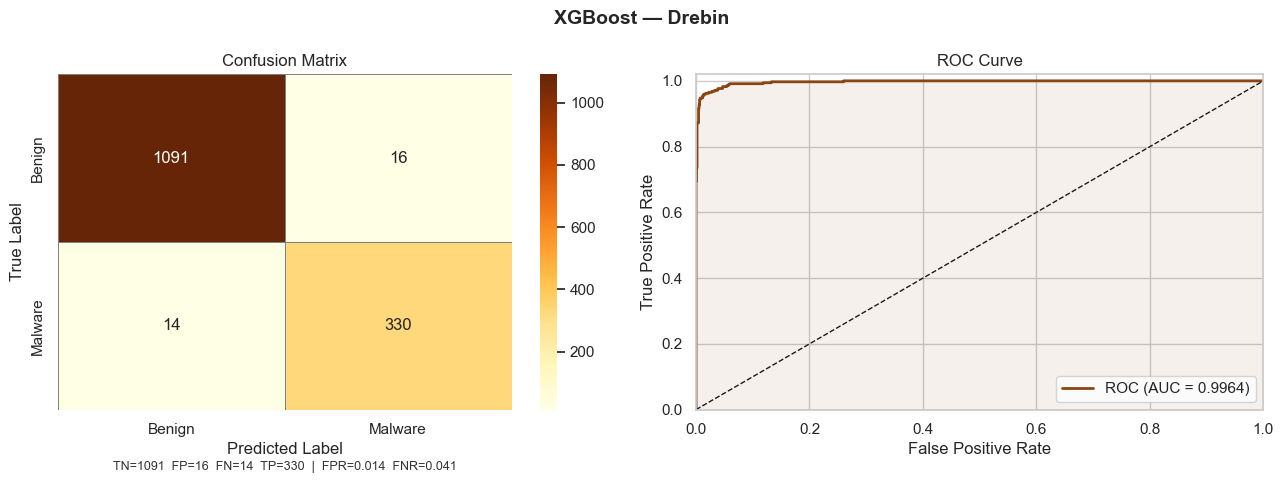

In [136]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('XGBoost — Drebin', fontsize=14, fontweight='bold')

cm_xd = confusion_matrix(y_drebin_test, y_xgb_drebin_pred)
sns.heatmap(cm_xd, annot=True, fmt='d', cmap='YlOrBr', ax=axes[0],
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray')
axes[0].set_title('Confusion Matrix')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
tn, fp, fn, tp = cm_xd.ravel()
axes[0].text(0.5, -0.18,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=axes[0].transAxes, ha='center', fontsize=9, color='#333')

fpr_xd, tpr_xd, _ = roc_curve(y_drebin_test, y_xgb_drebin_prob)
roc_auc_xd = auc(fpr_xd, tpr_xd)
axes[1].plot(fpr_xd, tpr_xd, color='saddlebrown', lw=2,
             label=f'ROC (AUC = {roc_auc_xd:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].fill_between(fpr_xd, tpr_xd, alpha=0.08, color='saddlebrown')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'xgb_drebin_eval.png'), bbox_inches='tight')
plt.show()


In [137]:
joblib.dump(xgb_cic,    f'{MODELS_DIR}/xgb_cic.joblib')
joblib.dump(xgb_drebin, f'{MODELS_DIR}/xgb_drebin.joblib')
print(f"Models saved to '{MODELS_DIR}/'")

print("\n" + "=" * 55)
print("XGBOOST — SUMMARY")
print("=" * 55)
print(f"  {'Metric':<14}  {'CICMalDroid':>12}  {'Drebin':>10}")
print("  " + "-" * 42)
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'F1-W', 'ROC-AUC']:
    cv = xgb_results['cic'][metric]
    dv = xgb_results['drebin'][metric]
    print(f"  {metric:<14}  {cv:>12.4f}  {dv:>10.4f}")


Models saved to 'models/'

XGBOOST — SUMMARY
  Metric           CICMalDroid      Drebin
  ------------------------------------------
  Accuracy              0.9835      0.9793
  Precision             0.9961      0.9538
  Recall                0.9854      0.9593
  F1                    0.9907      0.9565
  F1-W                  0.9838      0.9793
  ROC-AUC               0.9973      0.9964


---
## 10. MLP Neural Network

**Architecture**
- Solver: `Adam` | Activation: `ReLU` or `Tanh` | Regularisation: L2 (`alpha`)
- Hidden layers searched from: `(128,)` → `(256, 128, 64)`
- `early_stopping=True` prevents overfitting during both search and final training

> **Note:** `sklearn.MLPClassifier` does not support `class_weight` or `sample_weight`.  
> Class imbalance is addressed indirectly via the `f1_weighted` search metric and early stopping.


In [138]:
from sklearn.neural_network import MLPClassifier

mlp_results = {}

param_dist_mlp = {
    'hidden_layer_sizes': [(128,), (256,), (128, 64),
                           (256, 128), (128, 64, 32), (256, 128, 64)],
    'alpha'             : [1e-5, 1e-4, 1e-3, 1e-2],
    'learning_rate_init': [1e-3, 5e-4, 1e-4],
    'batch_size'        : [64, 128, 256],
    'activation'        : ['relu', 'tanh'],
}

print("MLP setup complete.")
print(f"CIC features : {X_cic_train.shape[1]}")
print(f"Drebin features: {X_drebin_train.shape[1]}")
print(f"Search space size: {6*4*3*3*2} combinations (sampling 10 randomly)")


MLP setup complete.
CIC features : 449
Drebin features: 215
Search space size: 432 combinations (sampling 10 randomly)


### 10.1 CICMalDroid 2020


In [139]:
# ~5-10 min | early_stopping inside each fold speeds up non-converging configs
print("RandomizedSearchCV (n_iter=10, cv=3, scoring=f1_weighted) …")

search_mlp_cic = RandomizedSearchCV(
    MLPClassifier(
        solver='adam',
        max_iter=300,
        early_stopping=True,
        n_iter_no_change=15,
        tol=1e-4,
        random_state=42
    ),
    param_distributions=param_dist_mlp,
    n_iter=10, cv=3,
    scoring='f1_weighted',
    random_state=42, n_jobs=-1, verbose=1,
    refit=True
)

t0 = time.time()
search_mlp_cic.fit(X_cic_train, y_cic_train)
print(f"\nSearch done in {time.time()-t0:.1f}s")
print(f"Best CV F1-weighted : {search_mlp_cic.best_score_:.4f}")
print(f"Best params         : {search_mlp_cic.best_params_}")


RandomizedSearchCV (n_iter=10, cv=3, scoring=f1_weighted) …
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-package


Search done in 11.2s
Best CV F1-weighted : 0.9586
Best params         : {'learning_rate_init': 0.001, 'hidden_layer_sizes': (256, 128, 64), 'batch_size': 128, 'alpha': 0.01, 'activation': 'relu'}


In [140]:
# Retrain on train+val with early stopping on an internal 10% hold-out
X_cic_tv = np.vstack([X_cic_train, X_cic_val])
y_cic_tv  = np.concatenate([y_cic_train, y_cic_val])

mlp_cic = MLPClassifier(
    **search_mlp_cic.best_params_,
    solver='adam',
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    tol=1e-5,
    random_state=42,
    verbose=False
)
mlp_cic.fit(X_cic_tv, y_cic_tv)
print(f"Final model converged in {mlp_cic.n_iter_} iterations.")

print("\nCICMalDroid MLP — Final Evaluation")
print("=" * 45)
m_mlp_cic, y_mlp_cic_pred, y_mlp_cic_prob = evaluate(
    mlp_cic, X_cic_test, y_cic_test, 'Test Set')
mlp_results['cic'] = m_mlp_cic

print(f"\nClassification Report:")
print(classification_report(y_cic_test, y_mlp_cic_pred,
                             target_names=['Benign', 'Malware']))


Final model converged in 59 iterations.

CICMalDroid MLP — Final Evaluation
  Test Set
    Accuracy    : 0.9635
    Precision   : 0.9763
    Recall      : 0.9830
    F1          : 0.9796
    F1-W        : 0.9631
    ROC-AUC     : 0.9443

Classification Report:
              precision    recall  f1-score   support

      Benign       0.85      0.80      0.83       250
     Malware       0.98      0.98      0.98      2054

    accuracy                           0.96      2304
   macro avg       0.91      0.89      0.90      2304
weighted avg       0.96      0.96      0.96      2304



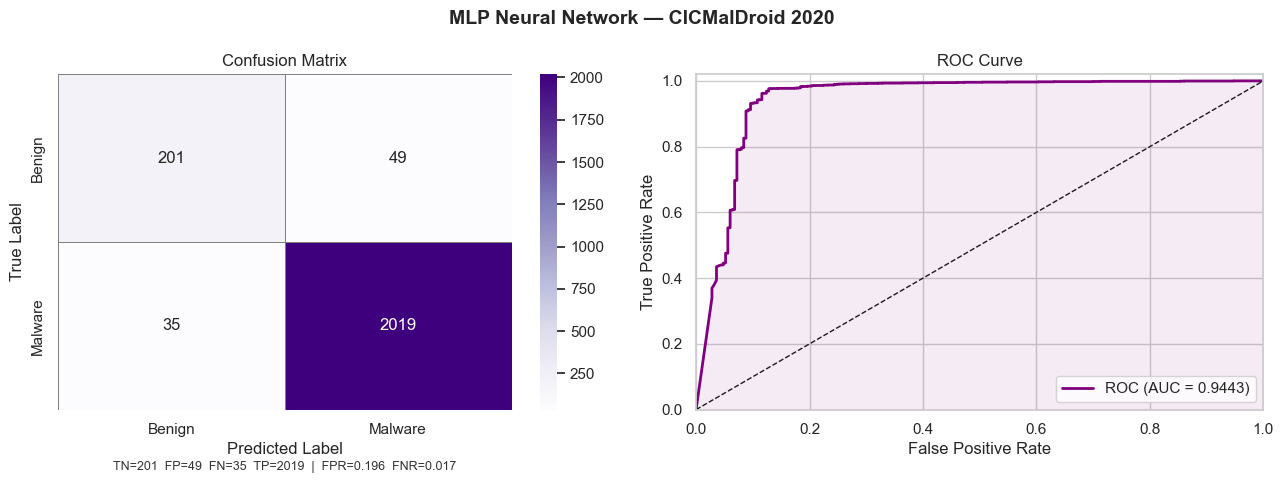

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('MLP Neural Network — CICMalDroid 2020', fontsize=14, fontweight='bold')

cm_m = confusion_matrix(y_cic_test, y_mlp_cic_pred)
sns.heatmap(cm_m, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray')
axes[0].set_title('Confusion Matrix', fontsize=12)
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
tn, fp, fn, tp = cm_m.ravel()
axes[0].text(0.5, -0.18,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=axes[0].transAxes, ha='center', fontsize=9, color='#333')

fpr_m, tpr_m, _ = roc_curve(y_cic_test, y_mlp_cic_prob)
roc_auc_m = auc(fpr_m, tpr_m)
axes[1].plot(fpr_m, tpr_m, color='purple', lw=2,
             label=f'ROC (AUC = {roc_auc_m:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].fill_between(fpr_m, tpr_m, alpha=0.08, color='purple')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontsize=12)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'mlp_cic_eval.png'), bbox_inches='tight')
plt.show()


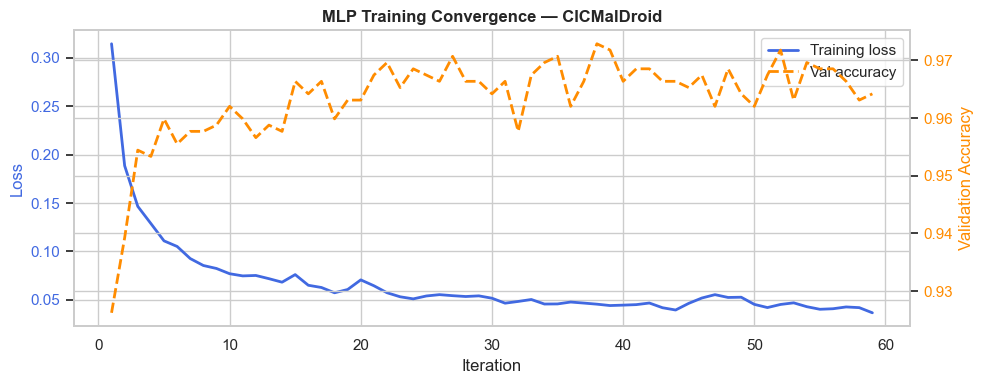

Stopped at iteration 59 | Best val accuracy: 0.9729


In [142]:
fig, ax = plt.subplots(figsize=(10, 4))

iters = range(1, len(mlp_cic.loss_curve_) + 1)
ax.plot(iters, mlp_cic.loss_curve_, color='royalblue', lw=2, label='Training loss')
ax.set_xlabel('Iteration')
ax.set_ylabel('Loss', color='royalblue')
ax.tick_params(axis='y', labelcolor='royalblue')

if hasattr(mlp_cic, 'validation_scores_') and mlp_cic.validation_scores_:
    ax2 = ax.twinx()
    ax2.plot(range(1, len(mlp_cic.validation_scores_) + 1),
             mlp_cic.validation_scores_,
             color='darkorange', lw=2, linestyle='--', label='Val accuracy')
    ax2.set_ylabel('Validation Accuracy', color='darkorange')
    ax2.tick_params(axis='y', labelcolor='darkorange')
    lines2, labels2 = ax2.get_legend_handles_labels()
else:
    lines2, labels2 = [], []

ax.set_title('MLP Training Convergence — CICMalDroid', fontsize=12, fontweight='bold')
lines1, labels1 = ax.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'mlp_cic_convergence.png'), bbox_inches='tight')
plt.show()
print(f"Stopped at iteration {mlp_cic.n_iter_} | "
      f"Best val accuracy: {max(mlp_cic.validation_scores_):.4f}")


### 10.2 Drebin (Secondary Dataset)


In [143]:
print("RandomizedSearchCV on Drebin (n_iter=10, cv=3) …")

search_mlp_drebin = RandomizedSearchCV(
    MLPClassifier(
        solver='adam',
        max_iter=300,
        early_stopping=True,
        n_iter_no_change=15,
        tol=1e-4,
        random_state=42
    ),
    param_distributions=param_dist_mlp,
    n_iter=10, cv=3,
    scoring='f1_weighted',
    random_state=42, n_jobs=-1, verbose=1,
    refit=True
)

t0 = time.time()
search_mlp_drebin.fit(X_drebin_train, y_drebin_train)
print(f"\nSearch done in {time.time()-t0:.1f}s")
print(f"Best CV F1-weighted : {search_mlp_drebin.best_score_:.4f}")
print(f"Best params         : {search_mlp_drebin.best_params_}")

# Retrain on train+val
X_drebin_tv = np.vstack([X_drebin_train, X_drebin_val])
y_drebin_tv  = np.concatenate([y_drebin_train, y_drebin_val])

mlp_drebin = MLPClassifier(
    **search_mlp_drebin.best_params_,
    solver='adam',
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    tol=1e-5,
    random_state=42,
    verbose=False
)
mlp_drebin.fit(X_drebin_tv, y_drebin_tv)
print(f"Final model converged in {mlp_drebin.n_iter_} iterations.")

print("\nDrebin MLP — Final Evaluation")
print("=" * 45)
m_mlp_drebin, y_mlp_drebin_pred, y_mlp_drebin_prob = evaluate(
    mlp_drebin, X_drebin_test, y_drebin_test, 'Test Set')
mlp_results['drebin'] = m_mlp_drebin

print(f"\nClassification Report:")
print(classification_report(y_drebin_test, y_mlp_drebin_pred,
                             target_names=['Benign', 'Malware']))


RandomizedSearchCV on Drebin (n_iter=10, cv=3) …
Fitting 3 folds for each of 10 candidates, totalling 30 fits


/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-package


Search done in 2.8s
Best CV F1-weighted : 0.9695
Best params         : {'learning_rate_init': 0.001, 'hidden_layer_sizes': (256, 128, 64), 'batch_size': 128, 'alpha': 0.01, 'activation': 'relu'}
Final model converged in 34 iterations.

Drebin MLP — Final Evaluation
  Test Set
    Accuracy    : 0.9711
    Precision   : 0.9290
    Recall      : 0.9506
    F1          : 0.9397
    F1-W        : 0.9712
    ROC-AUC     : 0.9886

Classification Report:
              precision    recall  f1-score   support

      Benign       0.98      0.98      0.98      1107
     Malware       0.93      0.95      0.94       344

    accuracy                           0.97      1451
   macro avg       0.96      0.96      0.96      1451
weighted avg       0.97      0.97      0.97      1451



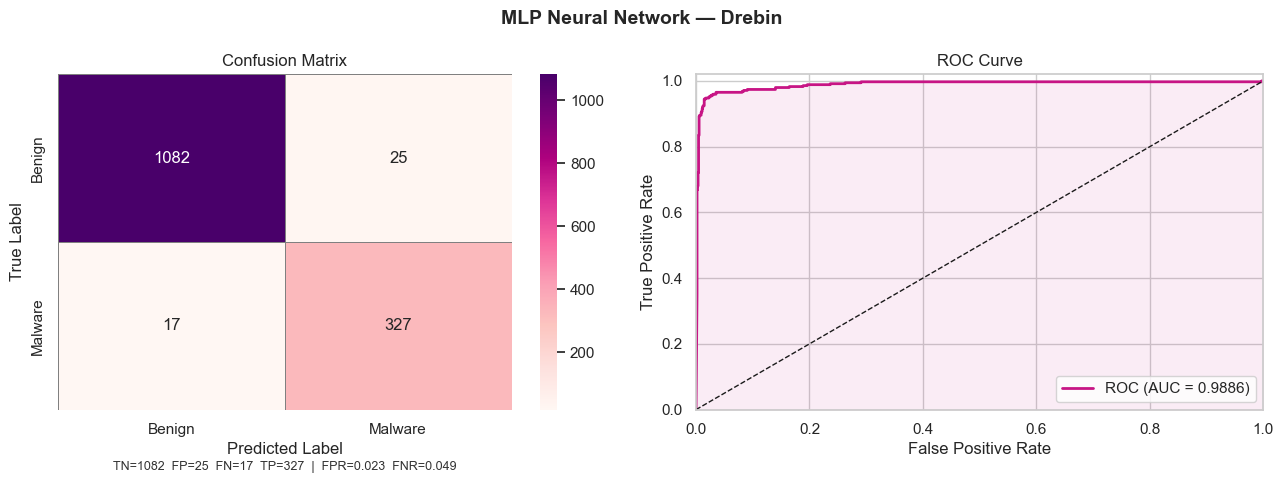

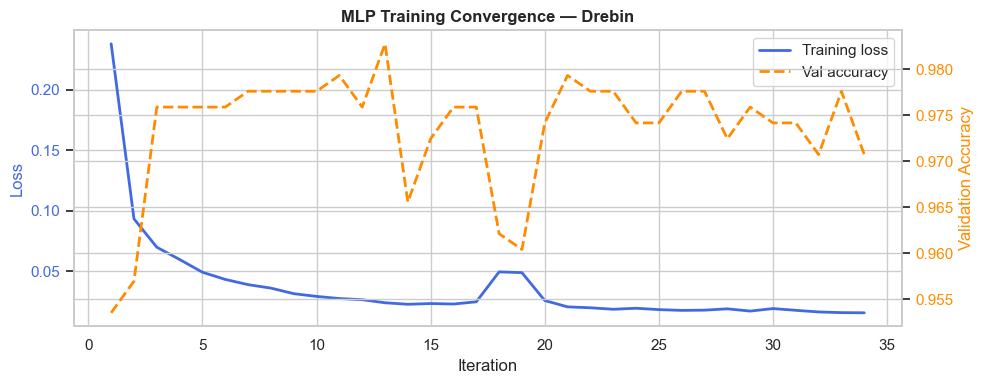

In [144]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('MLP Neural Network — Drebin', fontsize=14, fontweight='bold')

cm_md = confusion_matrix(y_drebin_test, y_mlp_drebin_pred)
sns.heatmap(cm_md, annot=True, fmt='d', cmap='RdPu', ax=axes[0],
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray')
axes[0].set_title('Confusion Matrix')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
tn, fp, fn, tp = cm_md.ravel()
axes[0].text(0.5, -0.18,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=axes[0].transAxes, ha='center', fontsize=9, color='#333')

fpr_md, tpr_md, _ = roc_curve(y_drebin_test, y_mlp_drebin_prob)
roc_auc_md = auc(fpr_md, tpr_md)
axes[1].plot(fpr_md, tpr_md, color='mediumvioletred', lw=2,
             label=f'ROC (AUC = {roc_auc_md:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].fill_between(fpr_md, tpr_md, alpha=0.08, color='mediumvioletred')
axes[1].set_xlim([0, 1]); axes[1].set_ylim([0, 1.02])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'mlp_drebin_eval.png'), bbox_inches='tight')
plt.show()

# Convergence curve
fig2, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(mlp_drebin.loss_curve_) + 1),
        mlp_drebin.loss_curve_, color='royalblue', lw=2, label='Training loss')
ax.set_xlabel('Iteration'); ax.set_ylabel('Loss', color='royalblue')
ax.tick_params(axis='y', labelcolor='royalblue')
if hasattr(mlp_drebin, 'validation_scores_') and mlp_drebin.validation_scores_:
    ax2 = ax.twinx()
    ax2.plot(range(1, len(mlp_drebin.validation_scores_) + 1),
             mlp_drebin.validation_scores_,
             color='darkorange', lw=2, linestyle='--', label='Val accuracy')
    ax2.set_ylabel('Validation Accuracy', color='darkorange')
    ax2.tick_params(axis='y', labelcolor='darkorange')
    lines2, labels2 = ax2.get_legend_handles_labels()
else:
    lines2, labels2 = [], []
ax.set_title('MLP Training Convergence — Drebin', fontsize=12, fontweight='bold')
lines1, labels1 = ax.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'mlp_drebin_convergence.png'), bbox_inches='tight')
plt.show()


In [145]:
joblib.dump(mlp_cic,    f'{MODELS_DIR}/mlp_cic.joblib')
joblib.dump(mlp_drebin, f'{MODELS_DIR}/mlp_drebin.joblib')
print(f"Models saved to '{MODELS_DIR}/'")

print("\n" + "=" * 55)
print("MLP NEURAL NETWORK — SUMMARY")
print("=" * 55)
print(f"  {'Metric':<14}  {'CICMalDroid':>12}  {'Drebin':>10}")
print("  " + "-" * 42)
for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'F1-W', 'ROC-AUC']:
    cv = mlp_results['cic'][metric]
    dv = mlp_results['drebin'][metric]
    print(f"  {metric:<14}  {cv:>12.4f}  {dv:>10.4f}")


Models saved to 'models/'

MLP NEURAL NETWORK — SUMMARY
  Metric           CICMalDroid      Drebin
  ------------------------------------------
  Accuracy              0.9635      0.9711
  Precision             0.9763      0.9290
  Recall                0.9830      0.9506
  F1                    0.9796      0.9397
  F1-W                  0.9631      0.9712
  ROC-AUC               0.9443      0.9886


---
## 11. Soft-Voting Ensemble

**Strategy:** average the predicted malware probabilities from all three base learners, then threshold at 0.5.

$$\hat{p}_{ensemble} = \frac{p_{RF} + p_{XGB} + p_{MLP}}{3}$$

| Model | Strength | Weakness |
|---|---|---|
| Random Forest | robust to noise, handles imbalance | high variance on rare class |
| XGBoost | strong gradient boosting, regularised | sensitive to outliers |
| MLP | learns non-linear interactions | no native class-weight support |
| **Ensemble** | compensates each model's weakness | requires all three models trained |

> **Pre-requisite:** RF, XGBoost, and MLP cells must be re-run after data cleaning (models need 449 CIC / 215 Drebin features).

In [146]:
import numpy as np
import joblib, os
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, auc)

PROCESSED_DIR = 'processed'
MODELS_DIR    = 'models'

# ── Load test data ────────────────────────────────────────────
X_cic_test    = np.load(f'{PROCESSED_DIR}/cic_X_test.npy')
y_cic_test    = np.load(f'{PROCESSED_DIR}/cic_y_test.npy')
X_drebin_test = np.load(f'{PROCESSED_DIR}/drebin_X_test.npy')
y_drebin_test = np.load(f'{PROCESSED_DIR}/drebin_y_test.npy')

# ── Load models ───────────────────────────────────────────────
rf_cic     = joblib.load(f'{MODELS_DIR}/rf_cic.joblib')
xgb_cic    = joblib.load(f'{MODELS_DIR}/xgb_cic.joblib')
mlp_cic    = joblib.load(f'{MODELS_DIR}/mlp_cic.joblib')
rf_drebin  = joblib.load(f'{MODELS_DIR}/rf_drebin.joblib')
xgb_drebin = joblib.load(f'{MODELS_DIR}/xgb_drebin.joblib')
mlp_drebin = joblib.load(f'{MODELS_DIR}/mlp_drebin.joblib')

# ── Compatibility check ───────────────────────────────────────
def check_compat(model, X, name):
    expected = model.n_features_in_
    actual   = X.shape[1]
    ok = expected == actual
    status = 'OK' if ok else f'MISMATCH — model expects {expected}, data has {actual}'
    print(f"  {name:<25}: {status}")
    return ok

print("Feature compatibility check:")
all_ok = True
for m, X, name in [
    (rf_cic,     X_cic_test,    'RF  — CICMalDroid'),
    (xgb_cic,    X_cic_test,    'XGB — CICMalDroid'),
    (mlp_cic,    X_cic_test,    'MLP — CICMalDroid'),
    (rf_drebin,  X_drebin_test, 'RF  — Drebin'),
    (xgb_drebin, X_drebin_test, 'XGB — Drebin'),
    (mlp_drebin, X_drebin_test, 'MLP — Drebin'),
]:
    all_ok &= check_compat(m, X, name)

if not all_ok:
    print("\n  Re-run RF / XGBoost / MLP training cells, then return here.")
else:
    print("\n  All models compatible — proceed.")

# ── Helpers ───────────────────────────────────────────────────
def get_probs(model, X):
    return model.predict_proba(X)[:, 1]

def soft_vote(prob_list):
    return np.mean(np.stack(prob_list, axis=1), axis=1)

def metrics_from_probs(y, p, label='', thresh=0.5):
    y_pred = (p >= thresh).astype(int)
    m = {
        'Accuracy' : accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall'   : recall_score(y, y_pred, zero_division=0),
        'F1'       : f1_score(y, y_pred, zero_division=0),
        'F1-W'     : f1_score(y, y_pred, average='weighted', zero_division=0),
        'ROC-AUC'  : roc_auc_score(y, p),
    }
    if label:
        print(f"  {label}")
        for k, v in m.items():
            print(f"    {k:<12}: {v:.4f}")
    return m, y_pred

all_results = {}  # {dataset: {model_name: metrics_dict}}

Feature compatibility check:
  RF  — CICMalDroid        : OK
  XGB — CICMalDroid        : OK
  MLP — CICMalDroid        : OK
  RF  — Drebin             : OK
  XGB — Drebin             : OK
  MLP — Drebin             : OK

  All models compatible — proceed.


### 11.1 CICMalDroid 2020

In [147]:
# Individual model probabilities
p_rf_cic  = get_probs(rf_cic,  X_cic_test)
p_xgb_cic = get_probs(xgb_cic, X_cic_test)
p_mlp_cic = get_probs(mlp_cic, X_cic_test)

# Soft-voting ensemble
p_ens_cic = soft_vote([p_rf_cic, p_xgb_cic, p_mlp_cic])

print("CICMalDroid — Test Set Evaluation")
print("=" * 48)
m_rf,  y_rf_pred  = metrics_from_probs(y_cic_test, p_rf_cic,  'Random Forest')
m_xgb, y_xgb_pred = metrics_from_probs(y_cic_test, p_xgb_cic, 'XGBoost')
m_mlp, y_mlp_pred = metrics_from_probs(y_cic_test, p_mlp_cic, 'MLP')
m_ens, y_ens_pred = metrics_from_probs(y_cic_test, p_ens_cic,  'Ensemble (soft vote)')

all_results['cic'] = {
    'Random Forest': m_rf, 'XGBoost': m_xgb,
    'MLP': m_mlp, 'Ensemble': m_ens,
}

print(f"\nEnsemble — Classification Report:")
print(classification_report(y_cic_test, y_ens_pred,
                             target_names=['Benign', 'Malware']))

CICMalDroid — Test Set Evaluation
  Random Forest
    Accuracy    : 0.9826
    Precision   : 0.9893
    Recall      : 0.9912
    F1          : 0.9903
    F1-W        : 0.9826
    ROC-AUC     : 0.9967
  XGBoost
    Accuracy    : 0.9835
    Precision   : 0.9961
    Recall      : 0.9854
    F1          : 0.9907
    F1-W        : 0.9838
    ROC-AUC     : 0.9973
  MLP
    Accuracy    : 0.9635
    Precision   : 0.9763
    Recall      : 0.9830
    F1          : 0.9796
    F1-W        : 0.9631
    ROC-AUC     : 0.9443
  Ensemble (soft vote)
    Accuracy    : 0.9831
    Precision   : 0.9903
    Recall      : 0.9907
    F1          : 0.9905
    F1-W        : 0.9831
    ROC-AUC     : 0.9967

Ensemble — Classification Report:
              precision    recall  f1-score   support

      Benign       0.92      0.92      0.92       250
     Malware       0.99      0.99      0.99      2054

    accuracy                           0.98      2304
   macro avg       0.96      0.96      0.96      2304
weig

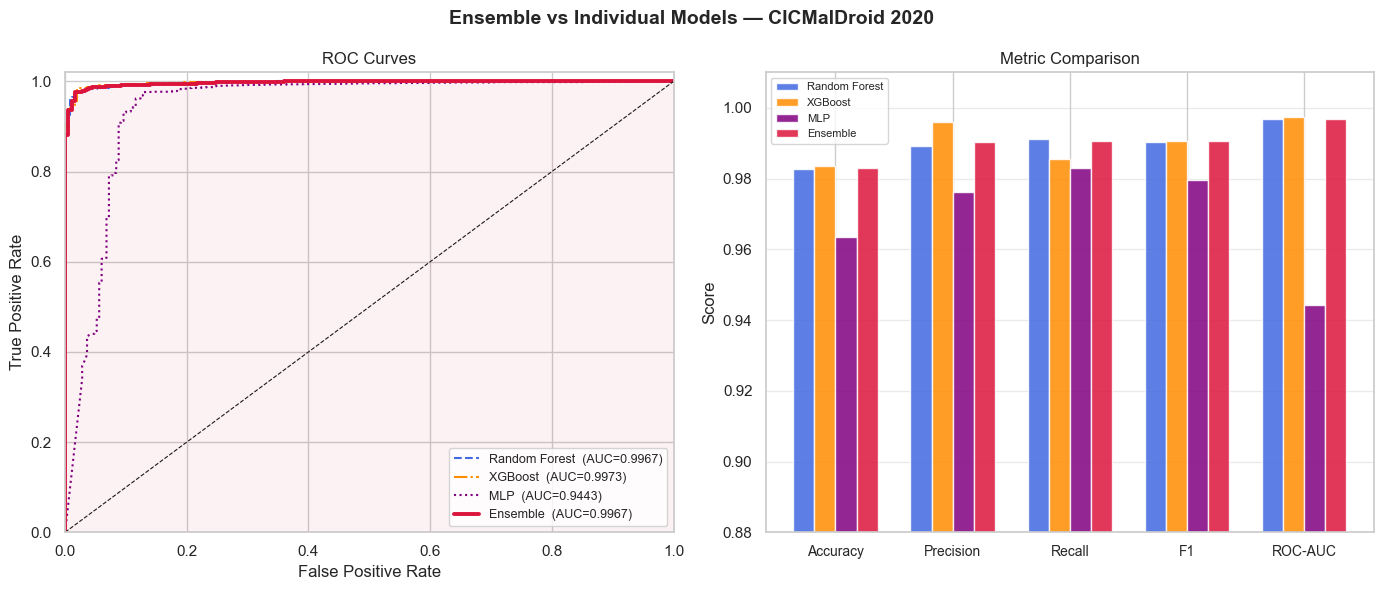

In [148]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ensemble vs Individual Models — CICMalDroid 2020',
             fontsize=14, fontweight='bold')

# ── ROC curves ───────────────────────────────────────────────
ax = axes[0]
palette = {'Random Forest': 'royalblue', 'XGBoost': 'darkorange',
           'MLP': 'purple', 'Ensemble': 'crimson'}
lw_map  = {'Random Forest': 1.5, 'XGBoost': 1.5, 'MLP': 1.5, 'Ensemble': 2.8}
ls_map  = {'Random Forest': '--', 'XGBoost': '-.', 'MLP': ':', 'Ensemble': '-'}

for (name, prob) in [('Random Forest', p_rf_cic), ('XGBoost', p_xgb_cic),
                     ('MLP', p_mlp_cic), ('Ensemble', p_ens_cic)]:
    fpr, tpr, _ = roc_curve(y_cic_test, prob)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=palette[name], lw=lw_map[name],
            linestyle=ls_map[name], label=f'{name}  (AUC={roc_auc:.4f})')

ax.fill_between(*roc_curve(y_cic_test, p_ens_cic)[:2], alpha=0.06, color='crimson')
ax.plot([0,1],[0,1],'k--',lw=0.8)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves', fontsize=12)
ax.legend(loc='lower right', fontsize=9)

# ── Metrics bar chart ─────────────────────────────────────────
ax2   = axes[1]
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
models = ['Random Forest', 'XGBoost', 'MLP', 'Ensemble']
x     = np.arange(len(metrics_to_plot))
width = 0.18

for i, (model, color) in enumerate(zip(models, palette.values())):
    vals = [all_results['cic'][model][m] for m in metrics_to_plot]
    bars = ax2.bar(x + i*width, vals, width, label=model,
                   color=color, alpha=0.85, edgecolor='white')

ax2.set_xticks(x + width*1.5)
ax2.set_xticklabels(metrics_to_plot, fontsize=10)
ax2.set_ylim([0.88, 1.01])
ax2.set_ylabel('Score')
ax2.set_title('Metric Comparison', fontsize=12)
ax2.legend(fontsize=8)
ax2.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'ensemble_cic_comparison.png'), bbox_inches='tight')
plt.show()

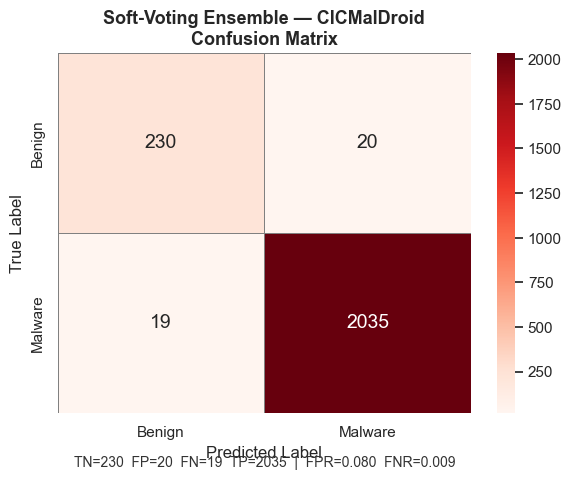

In [149]:
fig, ax = plt.subplots(figsize=(6, 5))
cm_e = confusion_matrix(y_cic_test, y_ens_pred)
sns.heatmap(cm_e, annot=True, fmt='d', cmap='Reds', ax=ax,
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray', annot_kws={'size': 14})
ax.set_title('Soft-Voting Ensemble — CICMalDroid\nConfusion Matrix',
             fontsize=13, fontweight='bold')
ax.set_ylabel('True Label'); ax.set_xlabel('Predicted Label')
tn, fp, fn, tp = cm_e.ravel()
ax.text(0.5, -0.15,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=ax.transAxes, ha='center', fontsize=10, color='#333')
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'ensemble_cic_cm.png'), bbox_inches='tight')
plt.show()

### 11.2 Drebin (Secondary Dataset)

In [150]:
p_rf_dr  = get_probs(rf_drebin,  X_drebin_test)
p_xgb_dr = get_probs(xgb_drebin, X_drebin_test)
p_mlp_dr = get_probs(mlp_drebin, X_drebin_test)
p_ens_dr = soft_vote([p_rf_dr, p_xgb_dr, p_mlp_dr])

print("Drebin — Test Set Evaluation")
print("=" * 48)
m_rf_dr,  _  = metrics_from_probs(y_drebin_test, p_rf_dr,  'Random Forest')
m_xgb_dr, _  = metrics_from_probs(y_drebin_test, p_xgb_dr, 'XGBoost')
m_mlp_dr, _  = metrics_from_probs(y_drebin_test, p_mlp_dr, 'MLP')
m_ens_dr, y_ens_dr_pred = metrics_from_probs(
    y_drebin_test, p_ens_dr, 'Ensemble (soft vote)')

all_results['drebin'] = {
    'Random Forest': m_rf_dr, 'XGBoost': m_xgb_dr,
    'MLP': m_mlp_dr, 'Ensemble': m_ens_dr,
}

print(f"\nEnsemble — Classification Report:")
print(classification_report(y_drebin_test, y_ens_dr_pred,
                             target_names=['Benign', 'Malware']))

Drebin — Test Set Evaluation
  Random Forest
    Accuracy    : 0.9738
    Precision   : 0.9722
    Recall      : 0.9157
    F1          : 0.9431
    F1-W        : 0.9735
    ROC-AUC     : 0.9940
  XGBoost
    Accuracy    : 0.9793
    Precision   : 0.9538
    Recall      : 0.9593
    F1          : 0.9565
    F1-W        : 0.9793
    ROC-AUC     : 0.9964
  MLP
    Accuracy    : 0.9711
    Precision   : 0.9290
    Recall      : 0.9506
    F1          : 0.9397
    F1-W        : 0.9712
    ROC-AUC     : 0.9886
  Ensemble (soft vote)
    Accuracy    : 0.9800
    Precision   : 0.9592
    Recall      : 0.9564
    F1          : 0.9578
    F1-W        : 0.9800
    ROC-AUC     : 0.9956

Ensemble — Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99      1107
     Malware       0.96      0.96      0.96       344

    accuracy                           0.98      1451
   macro avg       0.97      0.97      0.97      1451
weighted 

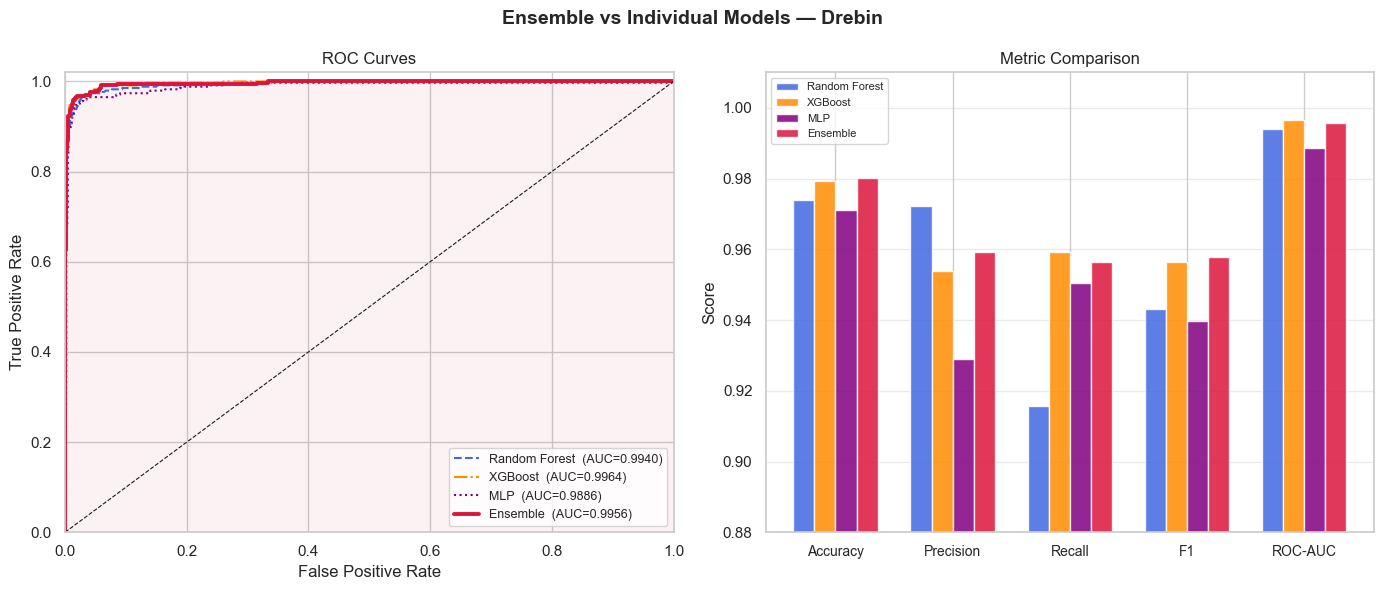

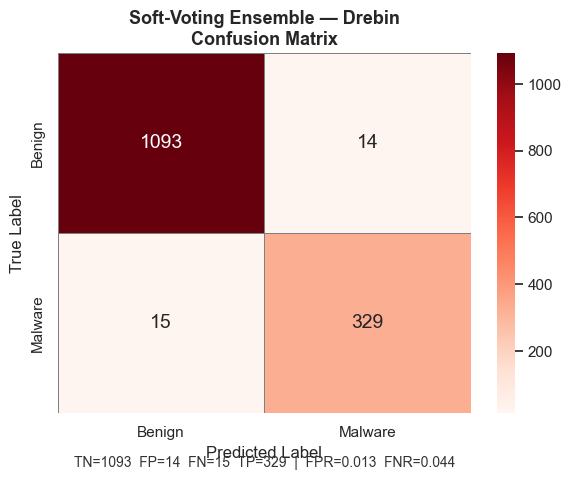

In [151]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Ensemble vs Individual Models — Drebin',
             fontsize=14, fontweight='bold')

ax = axes[0]
for (name, prob) in [('Random Forest', p_rf_dr), ('XGBoost', p_xgb_dr),
                     ('MLP', p_mlp_dr), ('Ensemble', p_ens_dr)]:
    fpr, tpr, _ = roc_curve(y_drebin_test, prob)
    ax.plot(fpr, tpr, color=palette[name], lw=lw_map[name],
            linestyle=ls_map[name],
            label=f'{name}  (AUC={auc(fpr,tpr):.4f})')
ax.fill_between(*roc_curve(y_drebin_test, p_ens_dr)[:2], alpha=0.06, color='crimson')
ax.plot([0,1],[0,1],'k--',lw=0.8)
ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves', fontsize=12)
ax.legend(loc='lower right', fontsize=9)

ax2 = axes[1]
for i, (model, color) in enumerate(zip(models, palette.values())):
    vals = [all_results['drebin'][model][m] for m in metrics_to_plot]
    ax2.bar(x + i*width, vals, width, label=model,
            color=color, alpha=0.85, edgecolor='white')
ax2.set_xticks(x + width*1.5)
ax2.set_xticklabels(metrics_to_plot, fontsize=10)
ax2.set_ylim([0.88, 1.01])
ax2.set_ylabel('Score')
ax2.set_title('Metric Comparison', fontsize=12)
ax2.legend(fontsize=8)
ax2.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'ensemble_drebin_comparison.png'), bbox_inches='tight')
plt.show()

# Ensemble confusion matrix
fig2, ax3 = plt.subplots(figsize=(6, 5))
cm_ed = confusion_matrix(y_drebin_test, y_ens_dr_pred)
sns.heatmap(cm_ed, annot=True, fmt='d', cmap='Reds', ax=ax3,
            xticklabels=['Benign', 'Malware'],
            yticklabels=['Benign', 'Malware'],
            linewidths=0.5, linecolor='gray', annot_kws={'size': 14})
ax3.set_title('Soft-Voting Ensemble — Drebin\nConfusion Matrix',
              fontsize=13, fontweight='bold')
ax3.set_ylabel('True Label'); ax3.set_xlabel('Predicted Label')
tn, fp, fn, tp = cm_ed.ravel()
ax3.text(0.5, -0.15,
    f'TN={tn}  FP={fp}  FN={fn}  TP={tp}  |  '
    f'FPR={fp/(fp+tn):.3f}  FNR={fn/(fn+tp):.3f}',
    transform=ax3.transAxes, ha='center', fontsize=10, color='#333')
plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'ensemble_drebin_cm.png'), bbox_inches='tight')
plt.show()

In [152]:
print("=" * 72)
print("FINAL RESULTS — ALL MODELS — BOTH DATASETS")
print("=" * 72)

for dataset in ['cic', 'drebin']:
    label = 'CICMalDroid 2020' if dataset == 'cic' else 'Drebin'
    print(f"\n  {label}")
    print(f"  {'Metric':<12}" + "".join(f"  {m:>14}" for m in models))
    print("  " + "-" * 68)
    for metric in ['Accuracy', 'Precision', 'Recall', 'F1', 'F1-W', 'ROC-AUC']:
        row = f"  {metric:<12}"
        for model in models:
            v = all_results[dataset][model][metric]
            # Bold best value with asterisk
            row += f"  {v:>14.4f}"
        print(row)

# Highlight ensemble improvement over best individual
print("\n" + "=" * 72)
print("ENSEMBLE GAIN over best individual model")
print("=" * 72)
for dataset in ['cic', 'drebin']:
    label = 'CICMalDroid' if dataset == 'cic' else 'Drebin'
    for metric in ['F1', 'ROC-AUC']:
        best_ind = max(all_results[dataset][m][metric]
                       for m in ['Random Forest', 'XGBoost', 'MLP'])
        ens_val  = all_results[dataset]['Ensemble'][metric]
        delta    = ens_val - best_ind
        sign     = '+' if delta >= 0 else ''
        print(f"  {label:<14} {metric:<10}: Ensemble={ens_val:.4f}  "
              f"Best individual={best_ind:.4f}  Delta={sign}{delta:.4f}")

# Save ensemble probabilities for future use
np.save(f'{MODELS_DIR}/ens_cic_probs_test.npy',    p_ens_cic)
np.save(f'{MODELS_DIR}/ens_drebin_probs_test.npy', p_ens_dr)
print(f"\nEnsemble probabilities saved to '{MODELS_DIR}/'")

FINAL RESULTS — ALL MODELS — BOTH DATASETS

  CICMalDroid 2020
  Metric         Random Forest         XGBoost             MLP        Ensemble
  --------------------------------------------------------------------
  Accuracy              0.9826          0.9835          0.9635          0.9831
  Precision             0.9893          0.9961          0.9763          0.9903
  Recall                0.9912          0.9854          0.9830          0.9907
  F1                    0.9903          0.9907          0.9796          0.9905
  F1-W                  0.9826          0.9838          0.9631          0.9831
  ROC-AUC               0.9967          0.9973          0.9443          0.9967

  Drebin
  Metric         Random Forest         XGBoost             MLP        Ensemble
  --------------------------------------------------------------------
  Accuracy              0.9738          0.9793          0.9711          0.9800
  Precision             0.9722          0.9538          0.9290          0.

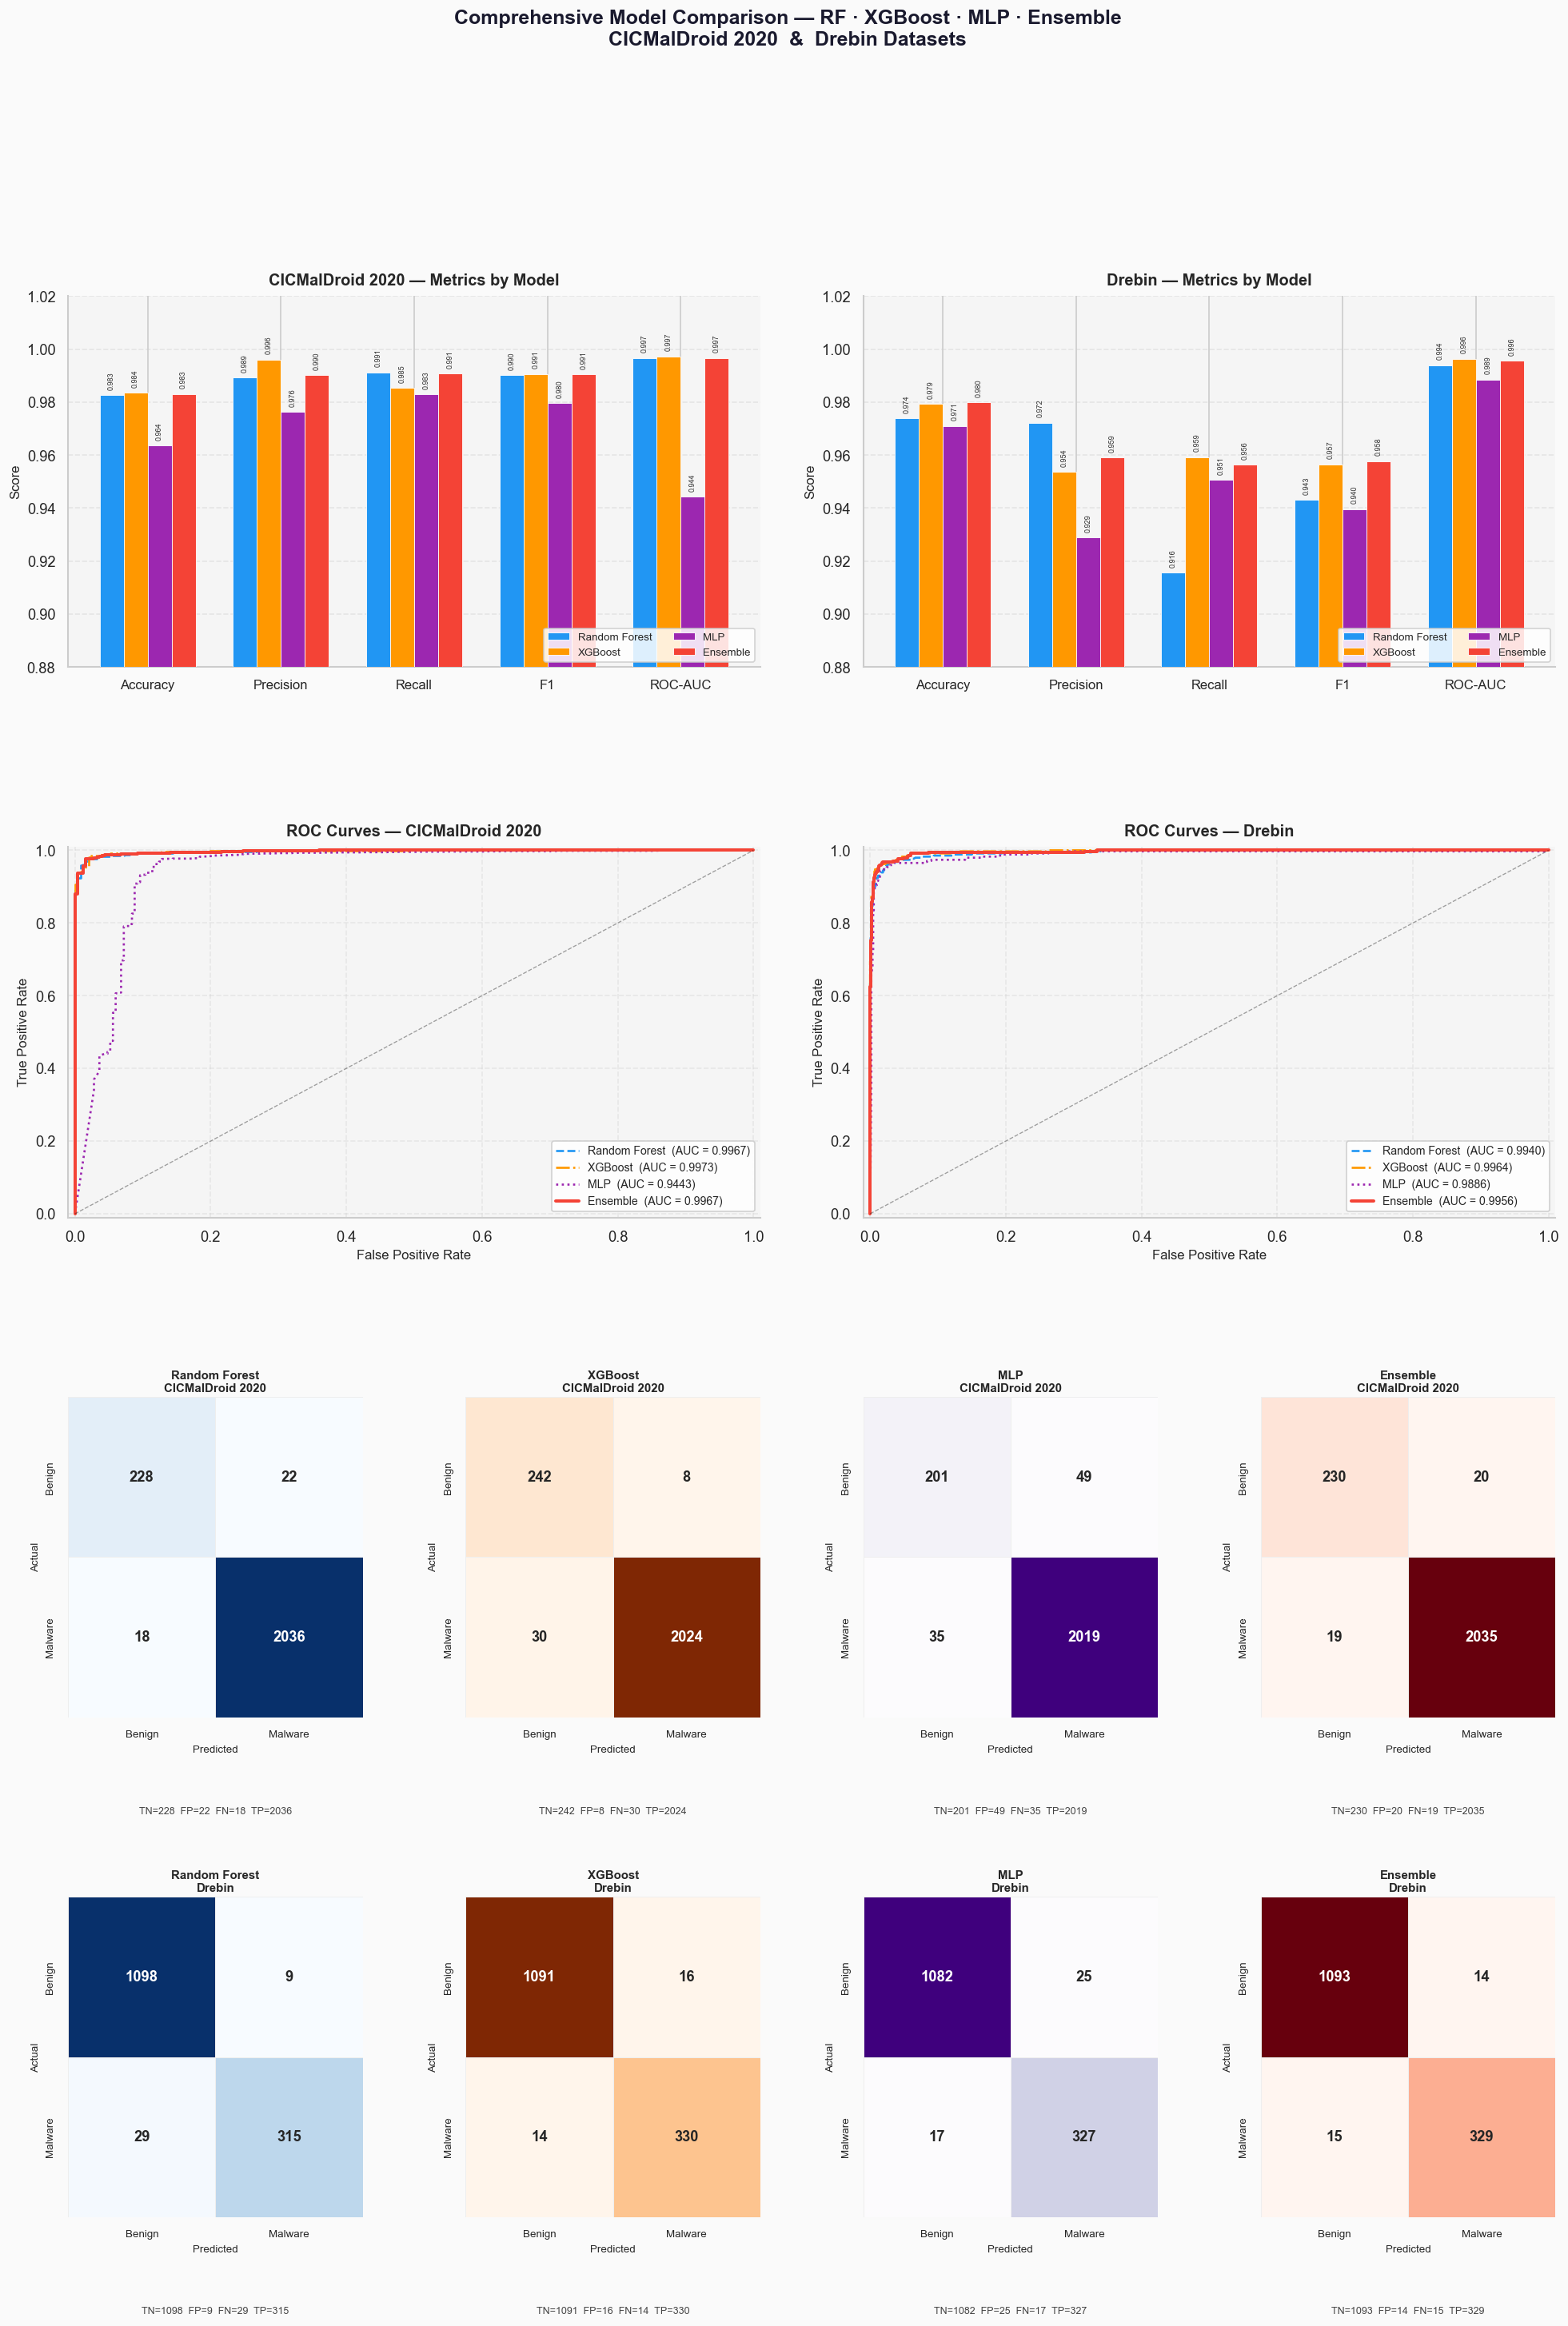

Saved → models/all_models_comparison.png


In [153]:
# ── 12. All-Models Comparison Figure ─────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc

MODELS   = ['Random Forest', 'XGBoost', 'MLP', 'Ensemble']
METRICS  = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
PALETTE  = {'Random Forest': '#2196F3', 'XGBoost': '#FF9800',
            'MLP': '#9C27B0', 'Ensemble': '#F44336'}

# ── Probabilities ─────────────────────────────────────────────────────────────
cic_probs  = {'Random Forest': p_rf_cic,  'XGBoost': p_xgb_cic,
              'MLP': p_mlp_cic, 'Ensemble': p_ens_cic}
dreb_probs = {'Random Forest': p_rf_dr,   'XGBoost': p_xgb_dr,
              'MLP': p_mlp_dr,  'Ensemble': p_ens_dr}

# ── Predictions (threshold 0.5) ────────────────────────────────────────────────
cic_preds  = {m: (p >= 0.5).astype(int) for m, p in cic_probs.items()}
dreb_preds = {m: (p >= 0.5).astype(int) for m, p in dreb_probs.items()}

# ── Build metric tables ────────────────────────────────────────────────────────
def metric_table(results, models, metrics):
    return np.array([[results[m][mt] for m in models] for mt in metrics])

cic_vals  = metric_table(all_results['cic'],    MODELS, METRICS)
dreb_vals = metric_table(all_results['drebin'], MODELS, METRICS)

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE: 4-row layout
#   Row 0 : grouped bar charts (metrics × models) — CIC  |  Drebin
#   Row 1 : ROC overlay                            — CIC  |  Drebin
#   Row 2 : confusion-matrix grid (4 cols)         — CIC  (all 4 models)
#   Row 3 : confusion-matrix grid (4 cols)         — Drebin (all 4 models)
# ─────────────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 26), dpi=120)
fig.patch.set_facecolor('#FAFAFA')
gs  = gridspec.GridSpec(4, 4, figure=fig,
                        hspace=0.52, wspace=0.35,
                        height_ratios=[1.1, 1.1, 0.95, 0.95])

# ── colour helper ─────────────────────────────────────────────────────────────
def bar_colours(models):
    return [PALETTE[m] for m in models]

# ═══════════════════════════════════════════════════════════════════════════════
# ROW 0 — Grouped bar charts
# ═══════════════════════════════════════════════════════════════════════════════
for col_idx, (title, vals) in enumerate([
        ('CICMalDroid 2020 — Metrics by Model', cic_vals),
        ('Drebin — Metrics by Model',            dreb_vals)]):

    ax = fig.add_subplot(gs[0, col_idx*2 : col_idx*2+2])
    n_metrics, n_models = vals.shape
    x     = np.arange(n_metrics)
    width = 0.18
    offsets = np.linspace(-(n_models-1)/2, (n_models-1)/2, n_models) * width

    for j, model in enumerate(MODELS):
        bars = ax.bar(x + offsets[j], vals[:, j], width,
                      label=model, color=PALETTE[model],
                      edgecolor='white', linewidth=0.5, zorder=3)
        for bar in bars:
            h = bar.get_height()
            if h > 0.88:
                ax.text(bar.get_x() + bar.get_width()/2, h + 0.002,
                        f'{h:.3f}', ha='center', va='bottom',
                        fontsize=5.5, color='#333', rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(METRICS, fontsize=10)
    ax.set_ylim(0.88, 1.02)
    ax.set_ylabel('Score', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.legend(fontsize=8, ncol=2, loc='lower right',
              framealpha=0.85, edgecolor='#CCC')
    ax.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)
    ax.set_facecolor('#F5F5F5')
    ax.spines[['top','right']].set_visible(False)

# ═══════════════════════════════════════════════════════════════════════════════
# ROW 1 — ROC curves
# ═══════════════════════════════════════════════════════════════════════════════
ls_map = {'Random Forest': '--', 'XGBoost': '-.', 'MLP': ':', 'Ensemble': '-'}
lw_map = {'Random Forest': 1.6,  'XGBoost': 1.6,  'MLP': 1.6,  'Ensemble': 2.4}

for col_idx, (title, probs, y_true) in enumerate([
        ('ROC Curves — CICMalDroid 2020', cic_probs,  y_cic_test),
        ('ROC Curves — Drebin',           dreb_probs, y_drebin_test)]):

    ax = fig.add_subplot(gs[1, col_idx*2 : col_idx*2+2])
    for model in MODELS:
        fpr, tpr, _ = roc_curve(y_true, probs[model])
        roc_auc = sk_auc(fpr, tpr)
        ax.plot(fpr, tpr,
                color=PALETTE[model],
                lw=lw_map[model],
                linestyle=ls_map[model],
                label=f'{model}  (AUC = {roc_auc:.4f})')

    ax.plot([0,1],[0,1], 'k--', lw=0.8, alpha=0.4)
    ax.set_xlim([-0.01, 1.01]); ax.set_ylim([-0.01, 1.01])
    ax.set_xlabel('False Positive Rate', fontsize=10)
    ax.set_ylabel('True Positive Rate', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.legend(fontsize=8.5, loc='lower right', framealpha=0.9, edgecolor='#CCC')
    ax.grid(linestyle='--', alpha=0.35)
    ax.set_facecolor('#F5F5F5')
    ax.spines[['top','right']].set_visible(False)

# ═══════════════════════════════════════════════════════════════════════════════
# ROWS 2–3 — Confusion matrices (4 models each dataset)
# ═══════════════════════════════════════════════════════════════════════════════
cm_cmaps = ['Blues', 'Oranges', 'Purples', 'Reds']

for row_idx, (dataset_label, preds, y_true) in enumerate([
        ('CICMalDroid 2020', cic_preds,  y_cic_test),
        ('Drebin',           dreb_preds, y_drebin_test)], start=2):

    class_labels = ['Benign', 'Malware']
    for col_idx, model in enumerate(MODELS):
        ax  = fig.add_subplot(gs[row_idx, col_idx])
        cm  = confusion_matrix(y_true, preds[model])
        tn, fp, fn, tp = cm.ravel()

        sns.heatmap(cm, annot=True, fmt='d', cmap=cm_cmaps[col_idx],
                    ax=ax, linewidths=0.6, linecolor='#EEE',
                    xticklabels=class_labels, yticklabels=class_labels,
                    annot_kws={'size': 11, 'weight': 'bold'},
                    cbar=False)
        ax.set_title(f'{model}\n{dataset_label}',
                     fontsize=9, fontweight='bold', pad=4)
        ax.set_xlabel('Predicted', fontsize=8)
        ax.set_ylabel('Actual', fontsize=8)
        ax.tick_params(labelsize=8)

        # TN/FP/FN/TP annotation below
        ax.text(0.5, -0.28,
                f'TN={tn}  FP={fp}  FN={fn}  TP={tp}',
                ha='center', va='top', fontsize=7.5,
                transform=ax.transAxes, color='#444')

# ── Master title ───────────────────────────────────────────────────────────────
fig.suptitle('Comprehensive Model Comparison — RF · XGBoost · MLP · Ensemble\n'
             'CICMalDroid 2020  &  Drebin Datasets',
             fontsize=15, fontweight='bold', y=0.995, color='#1A1A2E')

out_path = f'{MODELS_DIR}/all_models_comparison.png'
fig.savefig(out_path, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print(f"Saved → {out_path}")


In [154]:
# ── Shared setup for model comparison figures ─────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc as sk_auc

MODELS   = ['Random Forest', 'XGBoost', 'MLP', 'Ensemble']
METRICS  = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
PALETTE  = {'Random Forest': '#2196F3', 'XGBoost': '#FF9800',
            'MLP': '#9C27B0', 'Ensemble': '#F44336'}
CM_CMAPS = ['Blues', 'Oranges', 'Purples', 'Reds']
LS_MAP   = {'Random Forest': '--', 'XGBoost': '-.', 'MLP': ':', 'Ensemble': '-'}
LW_MAP   = {'Random Forest': 1.6,  'XGBoost': 1.6,  'MLP': 1.6,  'Ensemble': 2.4}

cic_probs  = {'Random Forest': p_rf_cic,  'XGBoost': p_xgb_cic,
              'MLP': p_mlp_cic, 'Ensemble': p_ens_cic}
dreb_probs = {'Random Forest': p_rf_dr,   'XGBoost': p_xgb_dr,
              'MLP': p_mlp_dr,  'Ensemble': p_ens_dr}
cic_preds  = {m: (p >= 0.5).astype(int) for m, p in cic_probs.items()}
dreb_preds = {m: (p >= 0.5).astype(int) for m, p in dreb_probs.items()}

def metric_table(results, models, metrics):
    return np.array([[results[m][mt] for m in models] for mt in metrics])

cic_vals  = metric_table(all_results['cic'],    MODELS, METRICS)
dreb_vals = metric_table(all_results['drebin'], MODELS, METRICS)

def make_comparison_figure(dataset_label, probs, preds, y_true, vals, fname):
    fig = plt.figure(figsize=(18, 18), dpi=130)
    fig.patch.set_facecolor('#FAFAFA')
    gs  = gridspec.GridSpec(3, 4, figure=fig,
                            hspace=0.55, wspace=0.38,
                            height_ratios=[1.0, 1.1, 1.1])

    # Row 0 — Confusion matrices
    class_labels = ['Benign', 'Malware']
    for col, model in enumerate(MODELS):
        ax = fig.add_subplot(gs[0, col])
        cm = confusion_matrix(y_true, preds[model])
        tn, fp, fn, tp = cm.ravel()
        sns.heatmap(cm, annot=True, fmt='d', cmap=CM_CMAPS[col],
                    ax=ax, linewidths=0.7, linecolor='#DDD',
                    xticklabels=class_labels, yticklabels=class_labels,
                    annot_kws={'size': 13, 'weight': 'bold'}, cbar=False)
        ax.set_title(model, fontsize=11, fontweight='bold', pad=6)
        ax.set_xlabel('Predicted', fontsize=9)
        ax.set_ylabel('Actual', fontsize=9)
        ax.tick_params(labelsize=9)
        ax.text(0.5, -0.22, f'TN={tn}  FP={fp}  FN={fn}  TP={tp}',
                ha='center', va='top', fontsize=8.5,
                transform=ax.transAxes, color='#444')

    # Row 1 — Grouped bar chart
    ax_bar = fig.add_subplot(gs[1, :])
    x       = np.arange(len(METRICS))
    width   = 0.18
    offsets = np.linspace(-(len(MODELS)-1)/2, (len(MODELS)-1)/2, len(MODELS)) * width
    for j, model in enumerate(MODELS):
        bars = ax_bar.bar(x + offsets[j], vals[:, j], width,
                          label=model, color=PALETTE[model],
                          edgecolor='white', linewidth=0.6, zorder=3)
        for bar in bars:
            h = bar.get_height()
            ax_bar.text(bar.get_x() + bar.get_width() / 2, h + 0.001,
                        f'{h:.4f}', ha='center', va='bottom',
                        fontsize=6.8, color='#222', rotation=90)
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(METRICS, fontsize=12)
    ax_bar.set_ylim(0.88, 1.025)
    ax_bar.set_ylabel('Score', fontsize=11)
    ax_bar.set_title(f'{dataset_label} — Metrics by Model',
                     fontsize=13, fontweight='bold', pad=10)
    ax_bar.legend(fontsize=10, ncol=4, loc='lower right',
                  framealpha=0.9, edgecolor='#CCC')
    ax_bar.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)
    ax_bar.set_facecolor('#F5F5F5')
    ax_bar.spines[['top', 'right']].set_visible(False)

    # Row 2 — ROC curves
    ax_roc = fig.add_subplot(gs[2, :])
    for model in MODELS:
        fpr, tpr, _ = roc_curve(y_true, probs[model])
        ax_roc.plot(fpr, tpr, color=PALETTE[model],
                    lw=LW_MAP[model], linestyle=LS_MAP[model],
                    label=f'{model}  (AUC = {sk_auc(fpr, tpr):.4f})')
    ax_roc.plot([0, 1], [0, 1], 'k--', lw=0.9, alpha=0.35, label='Random baseline')
    ax_roc.set_xlim([-0.01, 1.01]); ax_roc.set_ylim([-0.01, 1.01])
    ax_roc.set_xlabel('False Positive Rate', fontsize=11)
    ax_roc.set_ylabel('True Positive Rate', fontsize=11)
    ax_roc.set_title(f'{dataset_label} — ROC Curves',
                     fontsize=13, fontweight='bold', pad=10)
    ax_roc.legend(fontsize=10, loc='lower right', framealpha=0.9, edgecolor='#CCC')
    ax_roc.grid(linestyle='--', alpha=0.35)
    ax_roc.set_facecolor('#F5F5F5')
    ax_roc.spines[['top', 'right']].set_visible(False)

    fig.suptitle(f'Model Comparison — {dataset_label}\n'
                 'Random Forest  ·  XGBoost  ·  MLP  ·  Soft-Vote Ensemble',
                 fontsize=15, fontweight='bold', y=1.01, color='#1A1A2E')

    out_path = f'{MODELS_DIR}/{fname}'
    fig.savefig(out_path, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()
    print(f"Saved → {out_path}")

print("Setup complete.")


Setup complete.


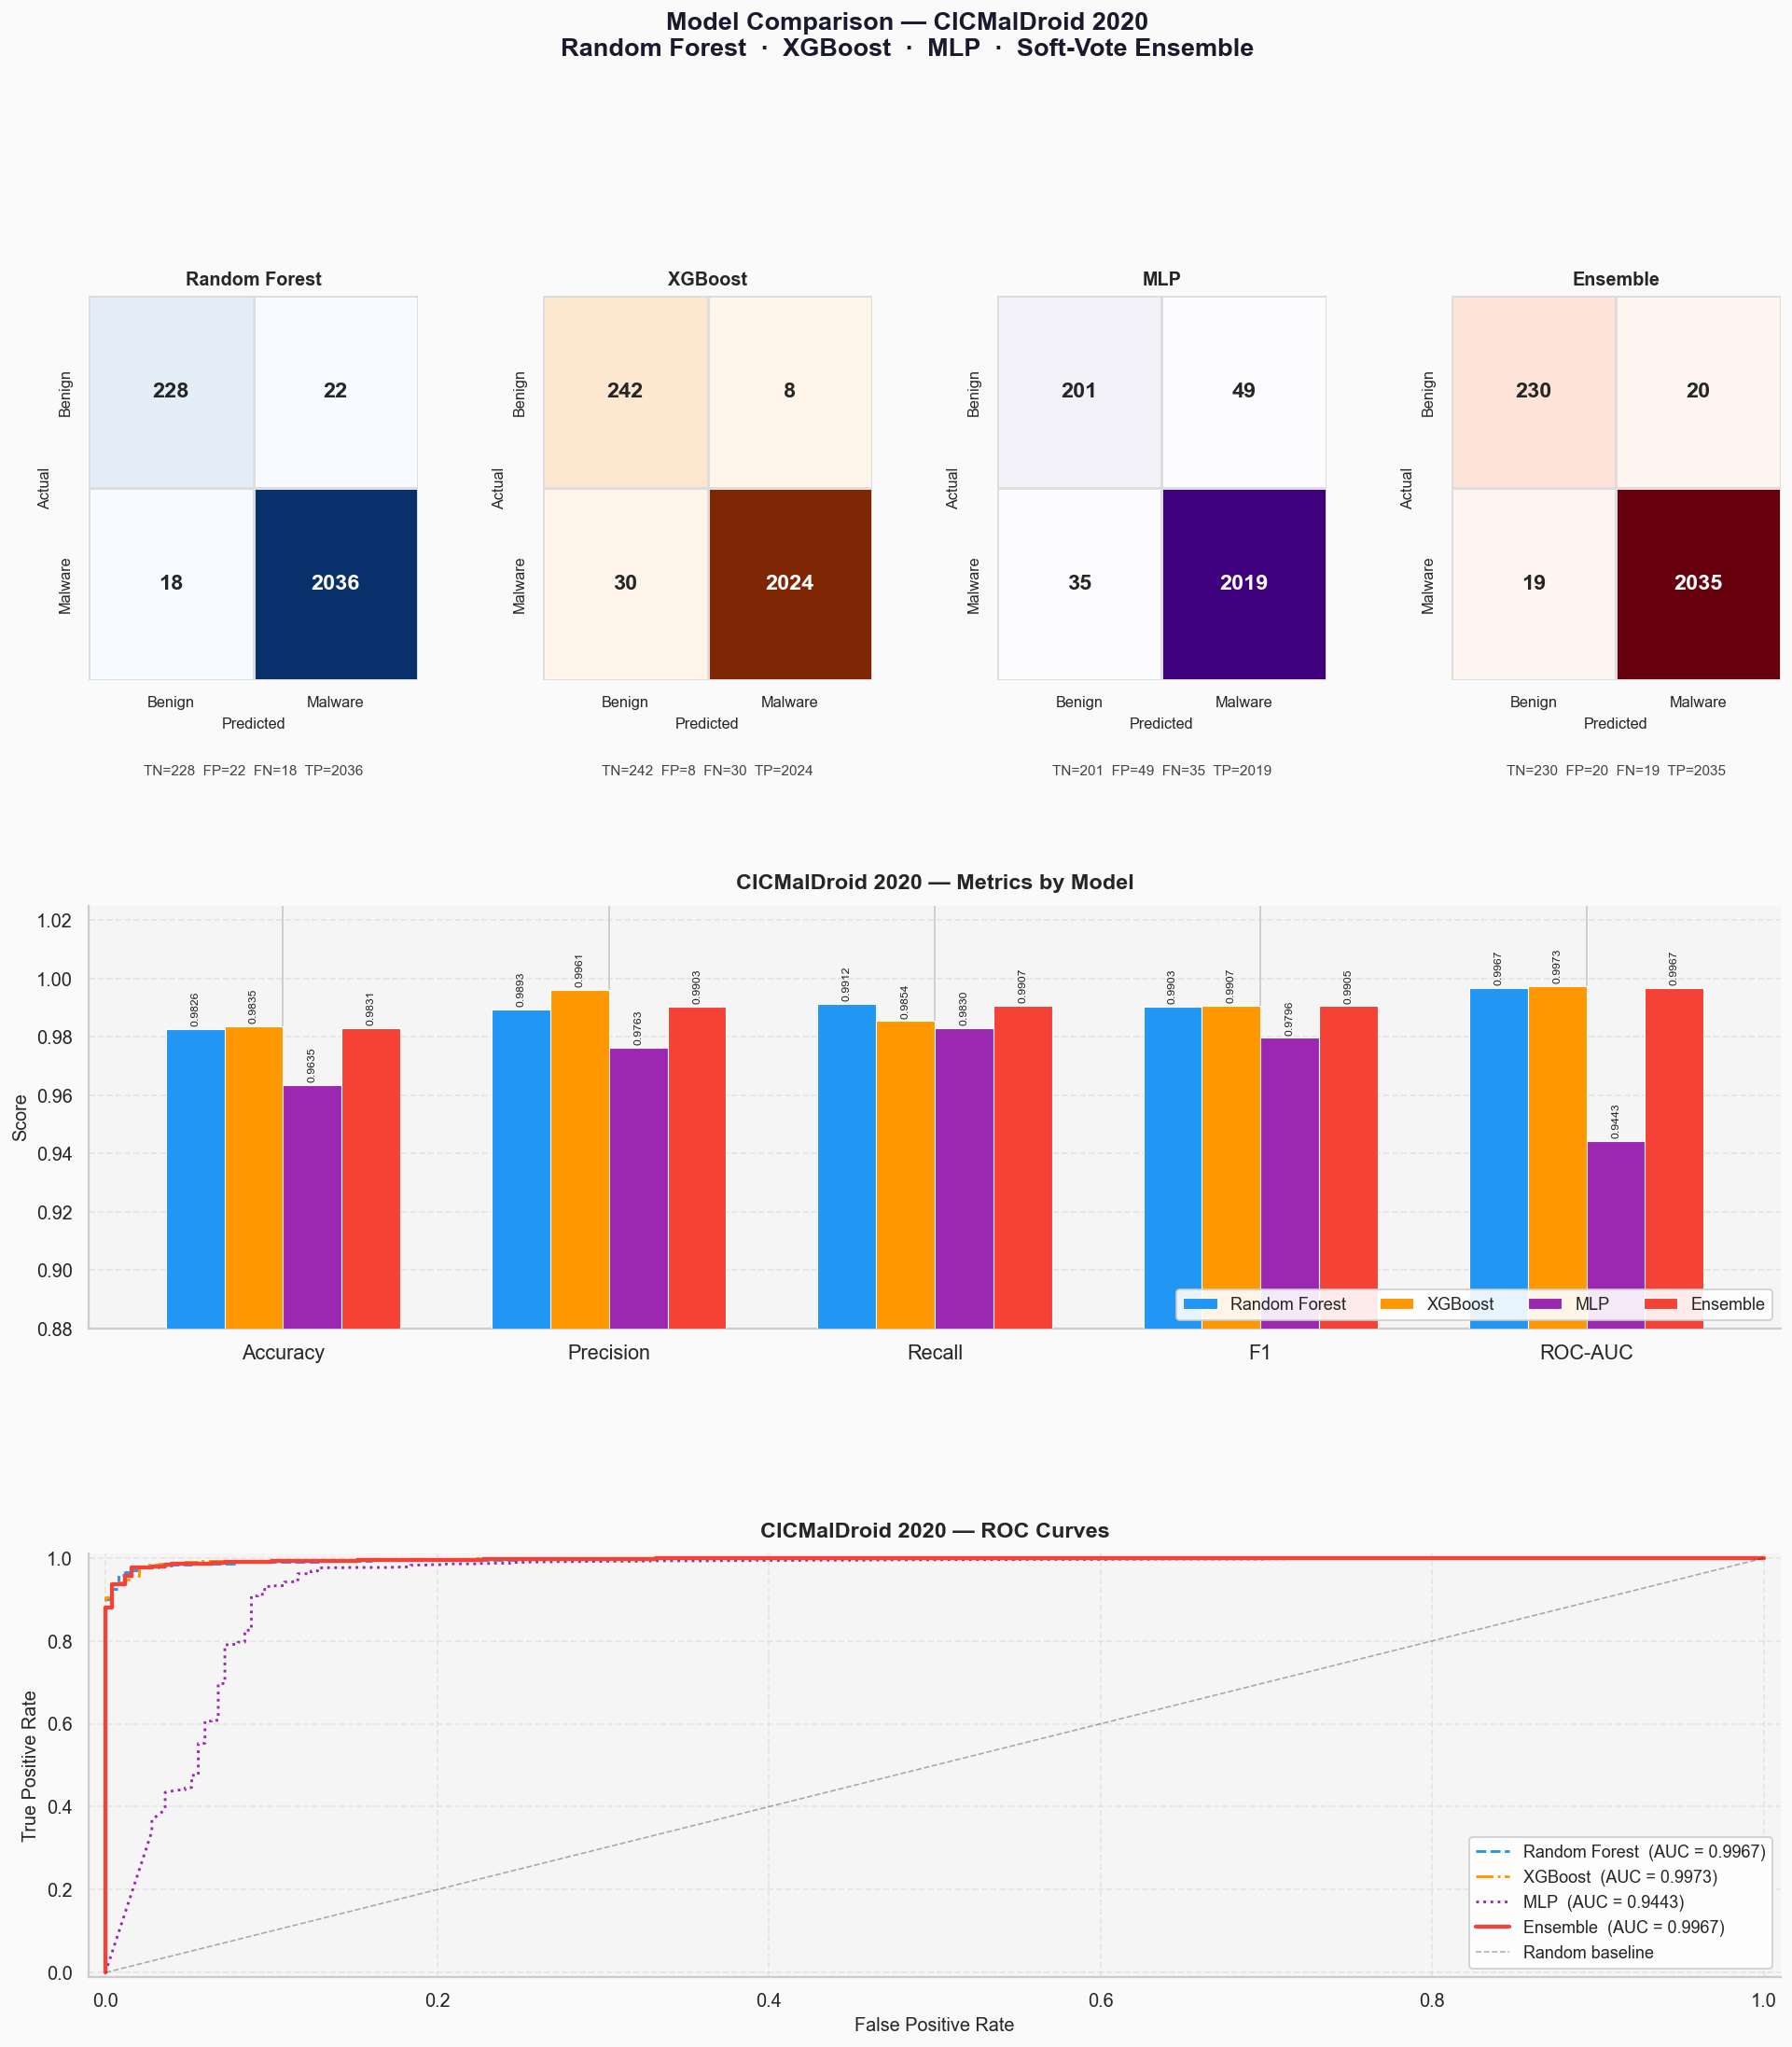

Saved → models/comparison_cic.png


In [155]:
make_comparison_figure(
    dataset_label = 'CICMalDroid 2020',
    probs         = cic_probs,
    preds         = cic_preds,
    y_true        = y_cic_test,
    vals          = cic_vals,
    fname         = 'comparison_cic.png',
)


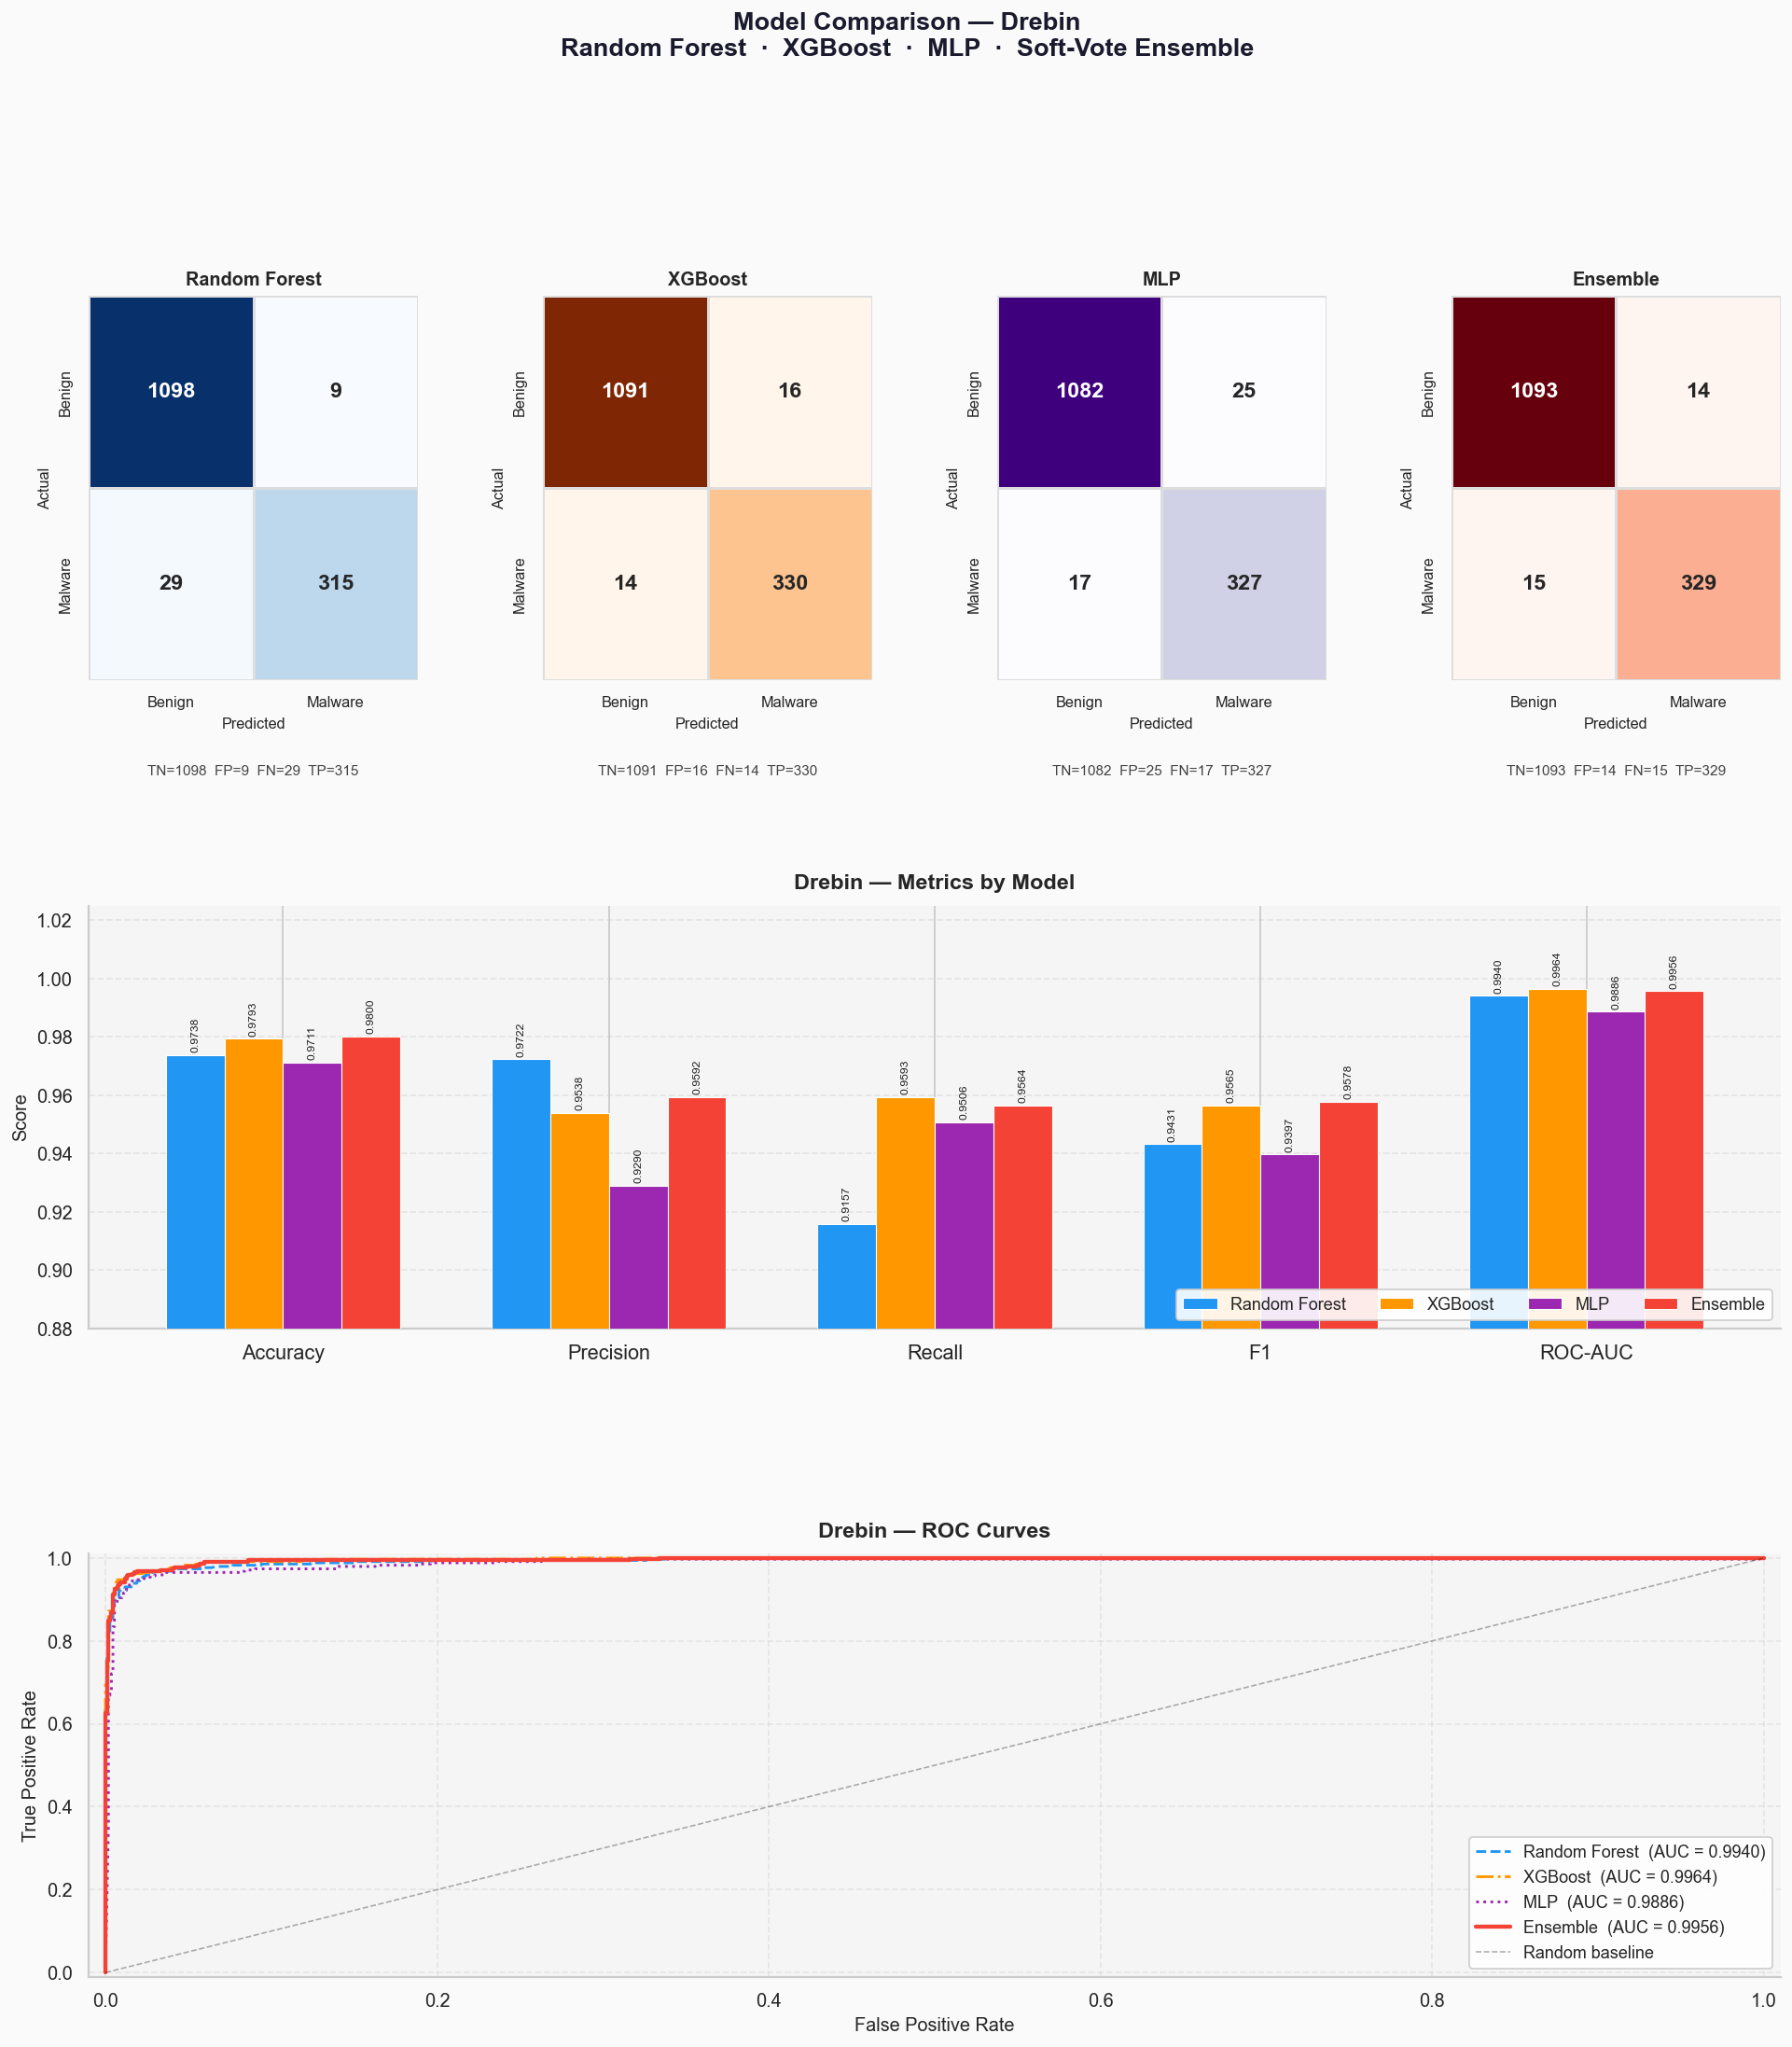

Saved → models/comparison_drebin.png


In [156]:
make_comparison_figure(
    dataset_label = 'Drebin',
    probs         = dreb_probs,
    preds         = dreb_preds,
    y_true        = y_drebin_test,
    vals          = dreb_vals,
    fname         = 'comparison_drebin.png',
)


Computing MLP permutation importance — ~1 min …


/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-package

Done.


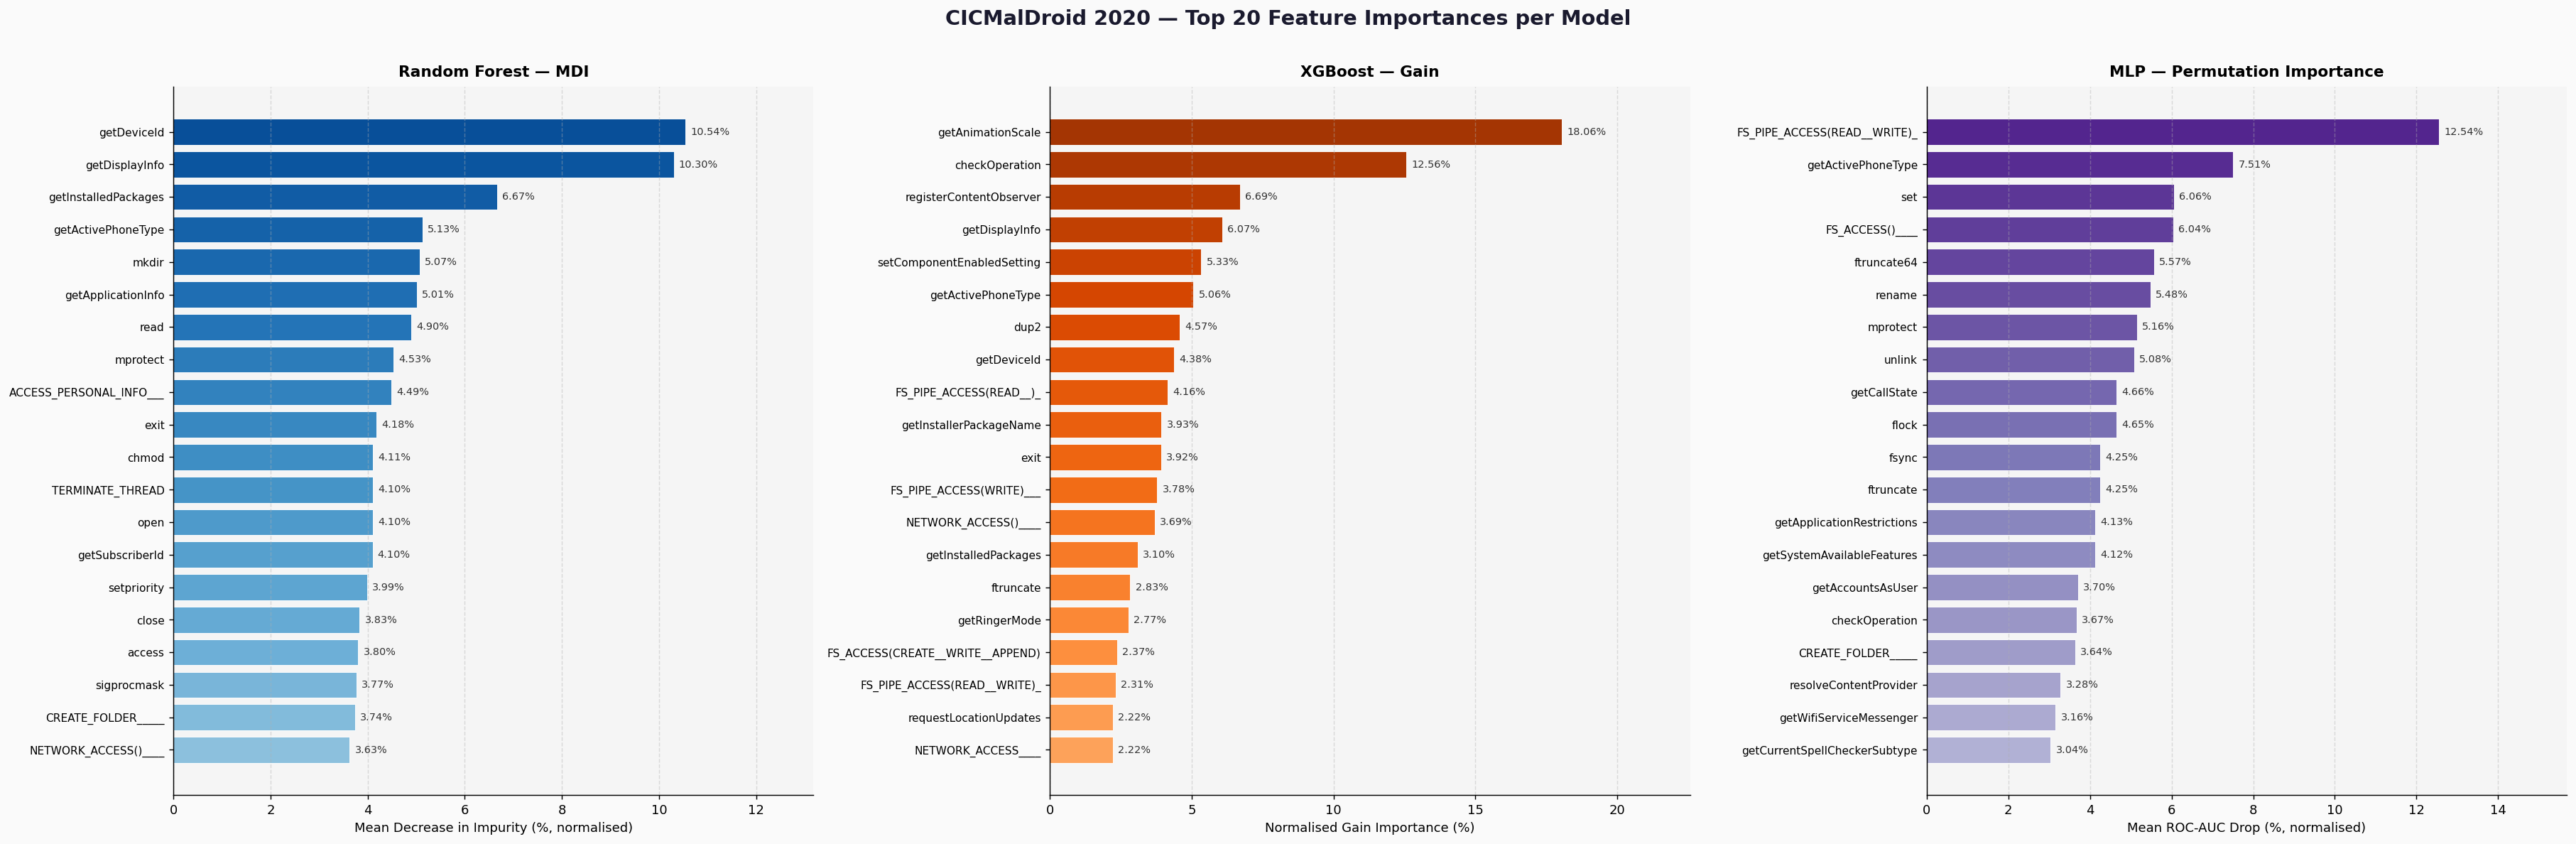

Saved → models/features_cic.png


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import json, joblib
from sklearn.inspection import permutation_importance

# ── Load everything ───────────────────────────────────────────────────────────
rf_cic  = joblib.load('models/rf_cic.joblib')
xgb_cic = joblib.load('models/xgb_cic.joblib')
mlp_cic = joblib.load('models/mlp_cic.joblib')

X_cic_test = np.load('processed/cic_X_test.npy')
y_cic_test = np.load('processed/cic_y_test.npy')

with open('processed/cic_features.json') as f:
    cic_features = json.load(f)

MODELS_DIR = 'models'
TOP_N = 20

# ── RF — MDI ──────────────────────────────────────────────────────────────────
rf_imp  = rf_cic.feature_importances_
rf_idx  = np.argsort(rf_imp)[::-1][:TOP_N]
rf_vals = rf_imp[rf_idx] / rf_imp[rf_idx].sum() * 100
rf_lbls = [cic_features[i][:36] for i in rf_idx]

# ── XGB — Gain (normalised) ───────────────────────────────────────────────────
gain_raw    = xgb_cic.get_booster().get_score(importance_type='gain')
gain_sorted = sorted(gain_raw.items(), key=lambda x: x[1], reverse=True)[:TOP_N]
xgb_lbls    = [cic_features[int(k[1:])] if k.startswith('f') else k for k, _ in gain_sorted]
xgb_lbls    = [l[:36] for l in xgb_lbls]
xgb_raw     = np.array([v for _, v in gain_sorted])
xgb_vals    = xgb_raw / xgb_raw.sum() * 100

# ── MLP — Permutation Importance (n_repeats=5, subsample for speed) ───────────
print("Computing MLP permutation importance — ~1 min …")
rng      = np.random.default_rng(42)
sub_idx  = rng.choice(len(X_cic_test), size=500, replace=False)
perm     = permutation_importance(mlp_cic,
                                  X_cic_test[sub_idx], y_cic_test[sub_idx],
                                  n_repeats=5, scoring='roc_auc',
                                  random_state=42, n_jobs=-1)
mlp_mean = perm.importances_mean
mlp_idx  = np.argsort(mlp_mean)[::-1][:TOP_N]
mlp_raw  = mlp_mean[mlp_idx].clip(0)          # clip negatives (noise → 0)
mlp_vals = mlp_raw / mlp_raw.sum() * 100 if mlp_raw.sum() > 0 else mlp_raw
mlp_lbls = [cic_features[i][:36] for i in mlp_idx]
print("Done.")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(28, 9), dpi=130)
fig.patch.set_facecolor('#FAFAFA')
fig.suptitle('CICMalDroid 2020 — Top 20 Feature Importances per Model',
             fontsize=16, fontweight='bold', y=1.01, color='#1A1A2E')

panels = [
    (axes[0], rf_lbls,  rf_vals,  'Random Forest — MDI',          plt.cm.Blues,   'Mean Decrease in Impurity (%, normalised)'),
    (axes[1], xgb_lbls, xgb_vals, 'XGBoost — Gain',               plt.cm.Oranges, 'Normalised Gain Importance (%)'),
    (axes[2], mlp_lbls, mlp_vals, 'MLP — Permutation Importance',  plt.cm.Purples, 'Mean ROC-AUC Drop (%, normalised)'),
]

for ax, lbls, vals, title, cmap, xlabel in panels:
    colours = cmap(np.linspace(0.42, 0.88, TOP_N))
    bars    = ax.barh(lbls[::-1], vals[::-1],
                      color=colours, edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars, vals[::-1]):
        ax.text(bar.get_width() + vals.max() * 0.01,
                bar.get_y() + bar.get_height() / 2,
                f'{val:.2f}%', va='center', fontsize=8, color='#333')
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlim(0, vals.max() * 1.25)
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.set_facecolor('#F5F5F5')
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='y', labelsize=8.5)

plt.tight_layout()
fig.savefig(f'{MODELS_DIR}/features_cic.png', bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print("Saved → models/features_cic.png")


Computing MLP permutation importance — ~30 s …


/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/nitharshan/Library/Python/3.9/lib/python/site-package

Done.


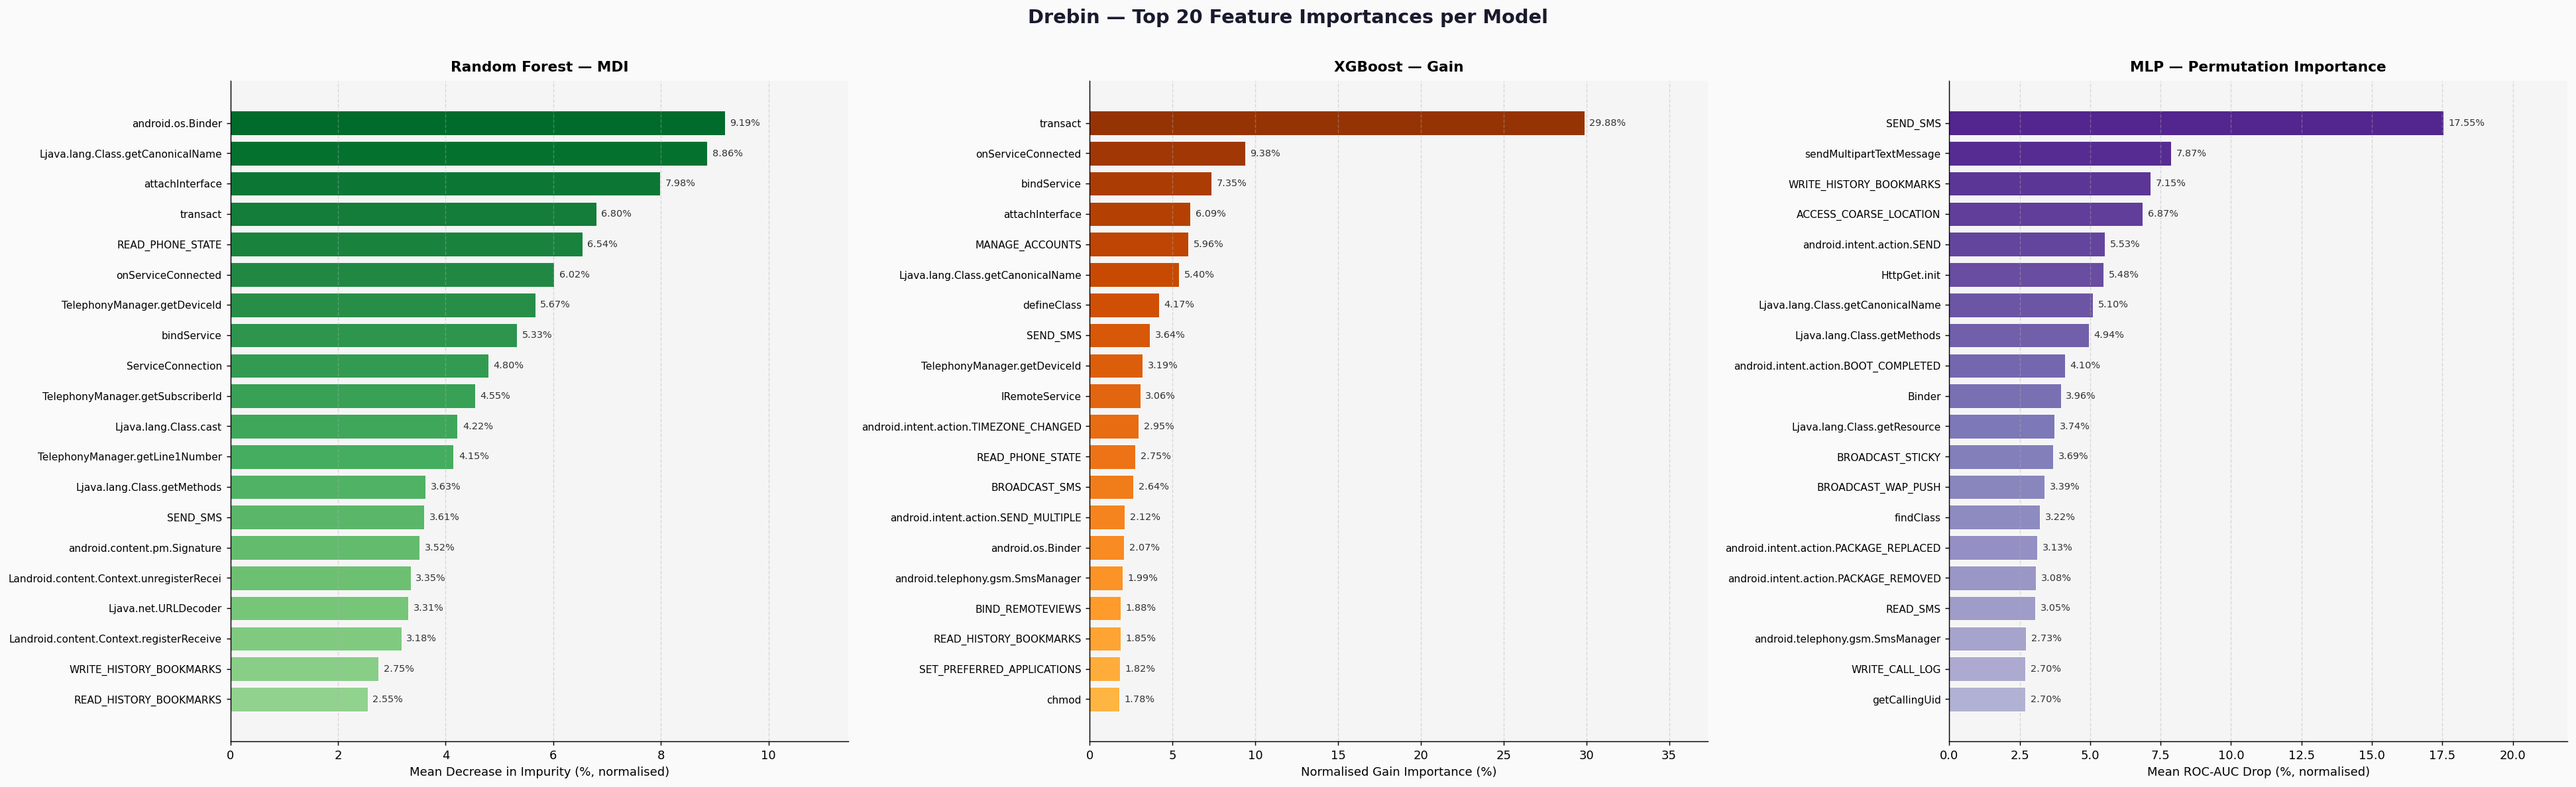

Saved → models/features_drebin.png


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import json, joblib
from sklearn.inspection import permutation_importance

# ── Load everything ───────────────────────────────────────────────────────────
rf_drebin  = joblib.load('models/rf_drebin.joblib')
xgb_drebin = joblib.load('models/xgb_drebin.joblib')
mlp_drebin = joblib.load('models/mlp_drebin.joblib')

X_drebin_test = np.load('processed/drebin_X_test.npy')
y_drebin_test = np.load('processed/drebin_y_test.npy')

with open('processed/drebin_features.json') as f:
    drebin_features = json.load(f)

MODELS_DIR = 'models'
TOP_N = 20

# ── RF — MDI ──────────────────────────────────────────────────────────────────
rf_imp  = rf_drebin.feature_importances_
rf_idx  = np.argsort(rf_imp)[::-1][:TOP_N]
rf_vals = rf_imp[rf_idx] / rf_imp[rf_idx].sum() * 100
rf_lbls = [drebin_features[i][:40] for i in rf_idx]

# ── XGB — Gain (normalised) ───────────────────────────────────────────────────
gain_raw    = xgb_drebin.get_booster().get_score(importance_type='gain')
gain_sorted = sorted(gain_raw.items(), key=lambda x: x[1], reverse=True)[:TOP_N]
xgb_lbls    = [drebin_features[int(k[1:])] if k.startswith('f') else k for k, _ in gain_sorted]
xgb_lbls    = [l[:40] for l in xgb_lbls]
xgb_raw     = np.array([v for _, v in gain_sorted])
xgb_vals    = xgb_raw / xgb_raw.sum() * 100

# ── MLP — Permutation Importance ─────────────────────────────────────────────
print("Computing MLP permutation importance — ~30 s …")
rng      = np.random.default_rng(42)
sub_idx  = rng.choice(len(X_drebin_test), size=500, replace=False)
perm     = permutation_importance(mlp_drebin,
                                  X_drebin_test[sub_idx], y_drebin_test[sub_idx],
                                  n_repeats=5, scoring='roc_auc',
                                  random_state=42, n_jobs=-1)
mlp_mean = perm.importances_mean
mlp_idx  = np.argsort(mlp_mean)[::-1][:TOP_N]
mlp_raw  = mlp_mean[mlp_idx].clip(0)
mlp_vals = mlp_raw / mlp_raw.sum() * 100 if mlp_raw.sum() > 0 else mlp_raw
mlp_lbls = [drebin_features[i][:40] for i in mlp_idx]
print("Done.")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(30, 9), dpi=130)
fig.patch.set_facecolor('#FAFAFA')
fig.suptitle('Drebin — Top 20 Feature Importances per Model',
             fontsize=16, fontweight='bold', y=1.01, color='#1A1A2E')

panels = [
    (axes[0], rf_lbls,  rf_vals,  'Random Forest — MDI',          plt.cm.Greens,  'Mean Decrease in Impurity (%, normalised)'),
    (axes[1], xgb_lbls, xgb_vals, 'XGBoost — Gain',               plt.cm.YlOrBr,  'Normalised Gain Importance (%)'),
    (axes[2], mlp_lbls, mlp_vals, 'MLP — Permutation Importance',  plt.cm.Purples, 'Mean ROC-AUC Drop (%, normalised)'),
]

for ax, lbls, vals, title, cmap, xlabel in panels:
    colours = cmap(np.linspace(0.42, 0.88, TOP_N))
    bars    = ax.barh(lbls[::-1], vals[::-1],
                      color=colours, edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars, vals[::-1]):
        ax.text(bar.get_width() + vals.max() * 0.01,
                bar.get_y() + bar.get_height() / 2,
                f'{val:.2f}%', va='center', fontsize=8, color='#333')
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlim(0, vals.max() * 1.25)
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    ax.set_facecolor('#F5F5F5')
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='y', labelsize=8.5)

plt.tight_layout()
fig.savefig(f'{MODELS_DIR}/features_drebin.png', bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print("Saved → models/features_drebin.png")
